# Visualitzacions

## Dinàmiques Espaciotemporals Searchlight

Aquest notebook resumeix el pipeline mínim per estudiar la informació espaciotemporal en Congruent vs Incongruent Pur amb dues visualitzacions finals reutilitzant la mateixa matriu d'accuracy:

1. Heatmap temps × elèctrode per a Theta i Alfa
2. Topomaps seqüencials + GIF per a Theta i Alfa

Flux de treball:

1. Seleccionar subjectes des del CSV i limitar-los amb `MAX_SUBJECTS`
2. Carregar epochs de forma robusta i ometre fitxers problemàtics
3. Definir canals comuns i finestres lliscants
4. Entrenar el searchlight per banda, elèctrode i finestra
5. Fer el contrast estadístic de grup i dibuixar els mapes
6. Generar els topomaps seqüencials i el GIF

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as patches
import matplotlib.gridspec as gridspec
import matplotlib as mpl
import mne
import importlib
from joblib import cpu_count
from IPython.display import display, Image
from mne.decoding import GeneralizingEstimator, cross_val_multiscore
from scipy.spatial.distance import pdist, squareform
import numpy.ma as ma
from scipy.ndimage import gaussian_filter1d

from scipy.stats import ttest_1samp
from scipy.ndimage import gaussian_filter
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.decomposition import PCA
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace

from mne_connectivity import spectral_connectivity_epochs
from mne_connectivity.viz import plot_connectivity_circle
from mne.datasets import fetch_fsaverage
from mne.minimum_norm import make_inverse_operator, apply_inverse

IN_COLAB = "COLAB_RELEASE_TAG" in os.environ

warnings.filterwarnings("ignore", category=RuntimeWarning)
mne.set_log_level("WARNING")

if IN_COLAB:
    DRIVE_ROOT = Path("/content/drive/MyDrive")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"
else:
    DRIVE_ROOT = Path(r"H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"

BASE_DIR = PROJECT_DIR
DATA_DIR = PROJECT_DIR / "02_Data" / "01_Preprocessed_epochs"
ANALYSIS_ROOT = PROJECT_DIR / "04_Anàlisi"
ANALYSIS_DIR = ANALYSIS_ROOT / "05_visualitzacions"
FIGURES_DIR = ANALYSIS_DIR / "figures"
CACHE_DIR = ANALYSIS_DIR / "cache"

for folder in (DATA_DIR, ANALYSIS_ROOT, ANALYSIS_DIR, FIGURES_DIR, CACHE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATA_FILES = sorted(DATA_DIR.glob("*.fif"))
SELECTED_SUBJECTS_CSV = PROJECT_DIR / "04_Anàlisi" / "01_exploracio" / "tables" / "subjectes_seleccionats.csv"
MAX_SUBJECTS = 22  # None = tots

# -------------------------
# Configuracio searchlight
# -------------------------
BANDS = {
    "theta": (5.0, 7.0),
    "alpha": (8.0, 12.0),
}

COND_CODES = {
    "C": [1, 2],
    "IP": [3, 4, 5, 6],
}

ANALYSIS_WINDOW = (0.0, 1.5)
WINDOW_SEC = 0.5
STEP_SEC = 0.1
CV_SPLITS = 5
RANDOM_STATE = 42
CLASSIFIER = "lda"  # "lda" o "logreg"
UNDERSAMPLE = True
N_JOBS = cpu_count() - 2 if cpu_count() > 2 else cpu_count()

print(f"Entorn: {'Colab' if IN_COLAB else 'Local'}")
print(f"Projecte: {PROJECT_DIR}")
print(f"Dades: {DATA_DIR}")
print(f"Resultats: {ANALYSIS_DIR}")
print(f"Fitxers FIF trobats: {len(DATA_FILES)}")
print(f"CSV subjectes: {SELECTED_SUBJECTS_CSV}")
print(f"MAX_SUBJECTS: {MAX_SUBJECTS}")

Entorn: Local
Projecte: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Dades: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\02_Data\01_Preprocessed_epochs
Resultats: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions
Fitxers FIF trobats: 47
CSV subjectes: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\subjectes_seleccionats.csv
MAX_SUBJECTS: 22


In [2]:
def sl_read_epochs_safe(fif_path):
    path_str = str(fif_path)
    try:
        ep = mne.read_epochs(path_str, preload=True)
        return ep, None
    except Exception as e:
        return None, f"{fif_path.name}: error llegint epochs ({type(e).__name__}: {e})"


def sl_choose_clf(kind="lda"):
    if kind == "logreg":
        base_clf = LogisticRegression(max_iter=1000, solver="liblinear", random_state=RANDOM_STATE)
    else:
        base_clf = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")
    return make_pipeline(StandardScaler(), base_clf)


def sl_windows(times, win_sec, step_sec):
    dt = float(np.median(np.diff(times)))
    sfreq = 1.0 / dt
    w = max(2, int(round(win_sec * sfreq)))
    s = max(1, int(round(step_sec * sfreq)))
    starts = np.arange(0, len(times) - w + 1, s)
    stops = starts + w
    labels = [f"{times[a]:.1f}-{times[b - 1]:.1f}s" for a, b in zip(starts, stops)]
    centers = np.array([times[a:b].mean() for a, b in zip(starts, stops)], dtype=float)
    return starts, stops, labels, centers


def sl_balance_epochs(epochs, y, seed=RANDOM_STATE):
    idx_c = np.where(y == 0)[0]
    idx_i = np.where(y == 1)[0]
    n_min = min(len(idx_c), len(idx_i))
    if n_min == 0:
        return None, None
    rng = np.random.default_rng(seed)
    keep = np.concatenate(
        [
            rng.choice(idx_c, n_min, replace=False),
            rng.choice(idx_i, n_min, replace=False),
        ]
    )
    rng.shuffle(keep)
    return epochs[keep], y[keep]


def sl_sort_electrodes(ch_names):
    region_rank = {
        "Fp": 0,
        "AF": 1,
        "F": 2,
        "FC": 3,
        "C": 4,
        "CP": 5,
        "P": 6,
        "PO": 7,
        "O": 8,
        "T": 9,
    }

    def _key(ch):
        prefix = "".join([c for c in ch if c.isalpha()])
        if prefix.startswith("Fp"):
            prefix = "Fp"
        rank = region_rank.get(prefix, 99)
        number = "".join([c for c in ch if c.isdigit()])
        number = int(number) if number else 0
        return (rank, number, ch)

    return sorted(ch_names, key=_key)


def sl_prepare_topomap_info(base_info, ch_names):
    """Assegura coordenades EEG per plot_topomap.

    Si l'info original no conté digitization points, crea un info nou
    amb un muntatge estàndard 10-20 per als canals disponibles.
    """
    info = base_info.copy()
    dig = info.get("dig", None)
    if dig is not None and len(dig) > 0:
        return info

    sfreq = float(info["sfreq"]) if "sfreq" in info else 250.0
    fallback = mne.create_info(ch_names=ch_names, sfreq=sfreq, ch_types="eeg")
    montage = mne.channels.make_standard_montage("standard_1020")
    fallback.set_montage(montage, on_missing="ignore")
    return fallback

## 1. Selecció de Subjectes

Llegim la llista des del CSV, eliminem duplicats i apliquem `MAX_SUBJECTS`.

In [3]:
sl_subject_targets = pd.read_csv(SELECTED_SUBJECTS_CSV, usecols=["subjecte"])["subjecte"].tolist()

if MAX_SUBJECTS is not None:
    sl_subject_targets = sl_subject_targets[:MAX_SUBJECTS]

sl_fif_by_subject = {p.stem: p for p in DATA_FILES}
sl_subject_paths = [sl_fif_by_subject[s] for s in sl_subject_targets if s in sl_fif_by_subject]

print(f"Nombre de subjectes: {len(sl_subject_paths)}")

Nombre de subjectes: 22


## 2. Càrrega Robusta d'Epochs

Intentem llegir cada fitxer `.fif` amb control d'errors. Si un fitxer falla, es registra a `sl_skipped` i el procés continua. Això normalment passa quan el fitxer està corrupte, inaccesible o no és un FIF llegible per MNE.

In [ ]:
sl_subjects = []

for si, fif_path in enumerate(sl_subject_paths):
    ep, err = sl_read_epochs_safe(fif_path)

    for ch_idx, ch_name in enumerate(ep.ch_names):
        if ep.info["chs"][ch_idx]["unit"] == 0:
            ep.info["chs"][ch_idx]["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
            ep.info["chs"][ch_idx]["unit_mul"] = mne.io.constants.FIFF.FIFF_UNITM_NONE

    ep.set_channel_types({ch: "eeg" for ch in ep.ch_names}, on_unit_change="ignore")
    ep = ep.copy().pick(mne.pick_types(ep.info, eeg=True))
    ep = ep.crop(tmin=ANALYSIS_WINDOW[0], tmax=ANALYSIS_WINDOW[1])

    events = ep.events[:, 2]
    mask_c = np.isin(events, COND_CODES["C"])
    mask_ip = np.isin(events, COND_CODES["IP"])

    ep = ep[mask_c | mask_ip].copy()
    y = np.where(np.isin(ep.events[:, 2], COND_CODES["C"]), 0, 1).astype(np.int8)

    if UNDERSAMPLE:
        ep_bal, y_bal = sl_balance_epochs(ep, y, seed=RANDOM_STATE + si)
        ep, y = ep_bal, y_bal

    sl_subjects.append({"subject": fif_path.stem, "epochs": ep, "y": y})

print(f"Subjectes vàlids per searchlight: {len(sl_subjects)}")

Subjectes vàlids per searchlight: 22


## 3. Intersecció de Canals Comuns

Unifiquem l'espai de canals entre subjectes per garantir comparabilitat en la classificació.

In [5]:
sl_common_ch = set(sl_subjects[0]["epochs"].ch_names)
for s in sl_subjects[1:]:
    sl_common_ch &= set(s["epochs"].ch_names)

sl_common_ch = [ch for ch in sl_subjects[0]["epochs"].ch_names if ch in sl_common_ch]
# Ordenar els canals comuns segons un ordre anatòmic aproximat
sl_common_ch = sl_sort_electrodes(sl_common_ch)

## 4. Definició de Finestres Temporals

Construïm les finestres lliscants de `SL_WINDOW_SEC` amb pas `SL_STEP_SEC`.

In [6]:
sl_times = sl_subjects[0]["epochs"].times
sl_starts, sl_stops, sl_window_labels, sl_window_centers = sl_windows(sl_times, WINDOW_SEC, STEP_SEC)

print(f"Finestres generades: {len(sl_starts)}")
print(f"Primera finestra: {sl_window_labels[0]} | Última: {sl_window_labels[-1]}")

Finestres generades: 11
Primera finestra: 0.0-0.5s | Última: 1.0-1.5s


## 5. Searchlight per Banda

Per a cada banda (Theta i Alfa), calculem la matriu `subjecte × elèctrode × finestra` d'accuracy.

In [7]:
cache_searchlight = CACHE_DIR / "cache_searchlight_results.npz"

try:
    z = np.load(cache_searchlight, allow_pickle=True)
    sl_results = {band: dict(z[band].item()) for band in z.files}
    print(f"Searchlight results loaded from cache: {cache_searchlight}")
except FileNotFoundError:
    sl_results = {}
    raw_info_topo = sl_subjects[0]["epochs"].copy().pick(sl_common_ch).info
    sl_info_topo = sl_prepare_topomap_info(raw_info_topo, sl_common_ch)

    for band_name, (l_freq, h_freq) in BANDS.items():
        print(f"\nProcessant banda {band_name} ({l_freq}-{h_freq} Hz) ...")
        subj_maps = []
        subj_names_ok = []

        for s in sl_subjects:
            ep_band = s["epochs"].copy().pick(sl_common_ch)
            ep_band.filter(l_freq=l_freq, h_freq=h_freq, method="fir", phase="zero-double", verbose=False)

            data = ep_band.get_data()  # trials x ch x time
            y = s["y"]

            power = np.empty((data.shape[0], data.shape[1], len(sl_starts)), dtype=float)
            for wi, (a, b) in enumerate(zip(sl_starts, sl_stops)):
                power[:, :, wi] = np.sqrt(np.mean(data[:, :, a:b] ** 2, axis=2))

            min_class = int(np.bincount(y).min())
            n_splits = min(CV_SPLITS, min_class)
            if n_splits < 2:
                continue

            cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
            clf = sl_choose_clf(CLASSIFIER)

            acc_map = np.full((power.shape[1], power.shape[2]), np.nan, dtype=float)
            for ci in range(power.shape[1]):
                for wi in range(power.shape[2]):
                    X = power[:, ci, wi].reshape(-1, 1)
                    scores = cross_val_score(clf, X, y, cv=cv, scoring="accuracy")
                    acc_map[ci, wi] = float(np.mean(scores))

            subj_maps.append(acc_map)
            subj_names_ok.append(s["subject"])

        if len(subj_maps) == 0:
            raise RuntimeError(f"Cap subjecte vàlid per banda {band_name}")

        acc_tensor = np.stack(subj_maps, axis=0)
        sl_results[band_name] = {
            "subjects": subj_names_ok,
            "ch_names": sl_common_ch,
            "window_labels": sl_window_labels,
            "window_centers": sl_window_centers,
            "acc": acc_tensor,
        }

        print(f"  Shape acc: {acc_tensor.shape} (subjectes, elèctrodes, finestres)")

    # Save to cache
    np.savez_compressed(cache_searchlight, **{band: np.array([sl_results[band]], dtype=object) for band in sl_results})
    print(f"Searchlight results saved to cache: {cache_searchlight}")

Searchlight results loaded from cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\cache\cache_searchlight_results.npz


## 6. Contrast Estadístic i Heatmaps

Fem `t-test` d'una mostra contra 0.5 i dibuixem heatmaps de `delta_acc` amb emmascarat visual de cel·les no significatives.


[theta]
  Subjectes: 22 | Elèctrodes: 60 | Finestres: 11
  Cel·les significatives p<0.05: 198/660

[alpha]
  Subjectes: 22 | Elèctrodes: 60 | Finestres: 11
  Cel·les significatives p<0.05: 431/660


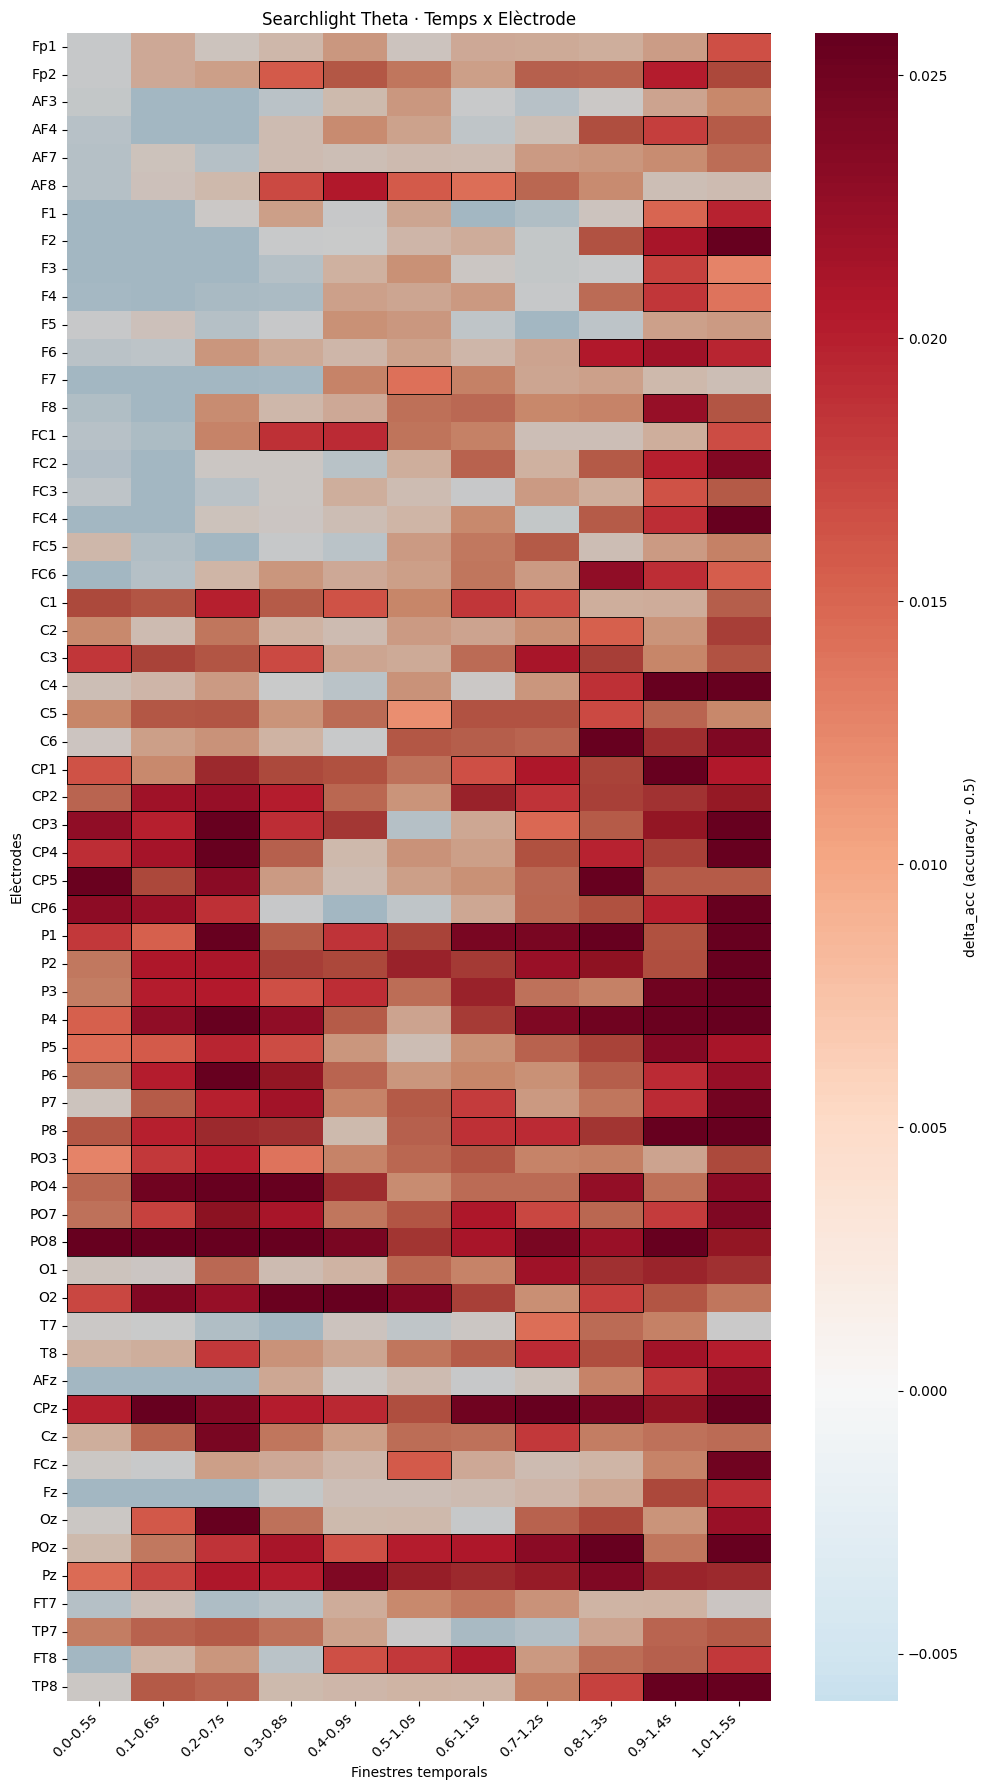

Heatmap desat: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\cache\searchlight_heatmap_theta.png


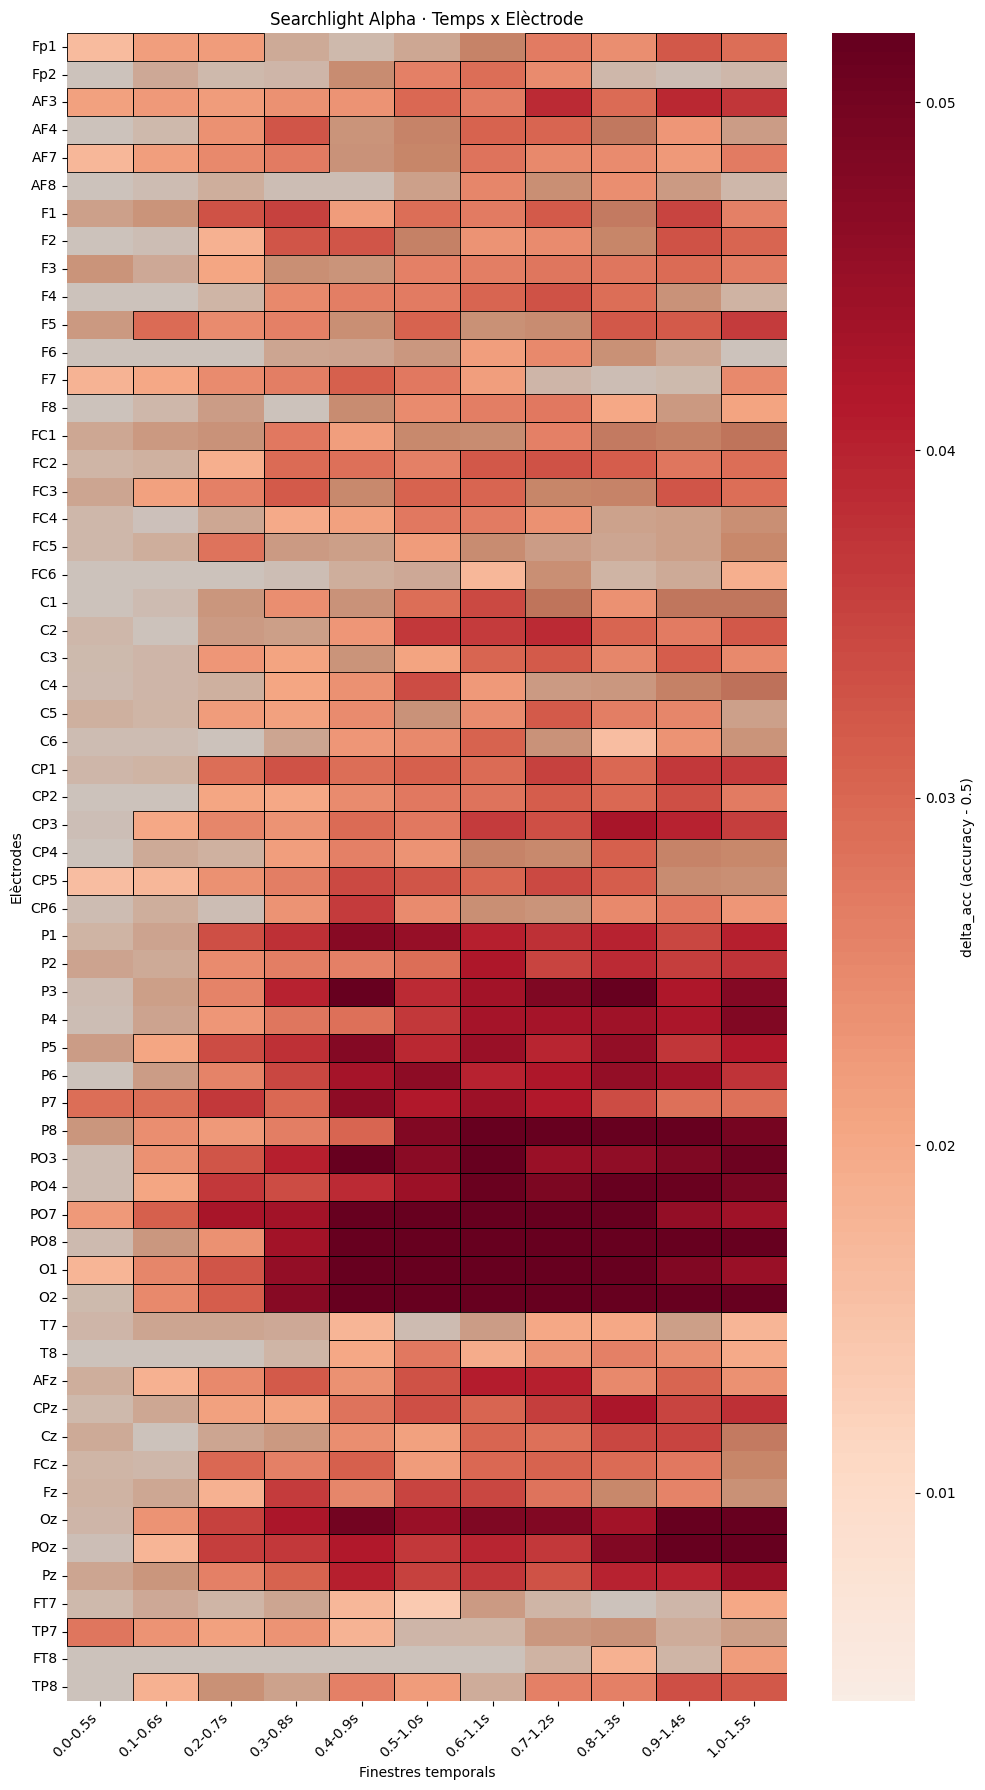

Heatmap desat: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\cache\searchlight_heatmap_alpha.png


In [8]:
sl_stats = {}

for band_name, d in sl_results.items():
    acc = d["acc"]  # S x C x W

    # T-test d'una mostra contra atzar=0.5 (one-tailed: greater)
    t_vals, p_vals = ttest_1samp(acc, popmean=0.5, axis=0, nan_policy="omit", alternative="greater")

    mean_acc = np.nanmean(acc, axis=0)
    delta_acc = mean_acc - 0.5
    sig = p_vals < 0.05

    sl_stats[band_name] = {
        "mean_acc": mean_acc,
        "delta_acc": delta_acc,
        "p_vals": p_vals,
        "sig": sig,
    }

    print(f"\n[{band_name}]")
    print(f"  Subjectes: {acc.shape[0]} | Elèctrodes: {acc.shape[1]} | Finestres: {acc.shape[2]}")
    print(f"  Cel·les significatives p<0.05: {int(np.sum(sig))}/{sig.size}")


# Heatmap per banda (mateixa matriu per als 2 tipus de figura)
for band_name, d in sl_results.items():
    ch_names = d["ch_names"]
    win_labels = d["window_labels"]

    delta = sl_stats[band_name]["delta_acc"]
    sig = sl_stats[band_name]["sig"]

    fig, ax = plt.subplots(figsize=(max(10, len(win_labels) * 0.8), max(8, len(ch_names) * 0.3)))
    sns.heatmap(
        delta,
        ax=ax,
        cmap="RdBu_r",
        center=0.0,
        vmin=np.nanpercentile(delta, 5),
        vmax=np.nanpercentile(delta, 95),
        xticklabels=win_labels,
        yticklabels=ch_names,
        cbar_kws={"label": "delta_acc (accuracy - 0.5)"},
    )

    # Enfosquir celles no significatives
    for i in range(delta.shape[0]):
        for j in range(delta.shape[1]):
            if not sig[i, j]:
                rect = patches.Rectangle((j, i), 1, 1, fill=True, color="black", alpha=0.18, linewidth=0)
                ax.add_patch(rect)
            else:
                rect = patches.Rectangle((j, i), 1, 1, fill=False, edgecolor="black", linewidth=0.6)
                ax.add_patch(rect)

    ax.set_title(f"Searchlight {band_name.capitalize()} · Temps x Elèctrode")
    ax.set_xlabel("Finestres temporals")
    ax.set_ylabel("Elèctrodes")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    out_png = CACHE_DIR / f"searchlight_heatmap_{band_name}.png"
    plt.savefig(out_png, dpi=160, bbox_inches="tight")
    plt.show()
    print(f"Heatmap desat: {out_png}")

## 7. Topomaps Seqüencials i GIF

A partir de la mateixa matriu d'accuracy mitjana, es genera un topomap per finestra i s'uneixen en un GIF.

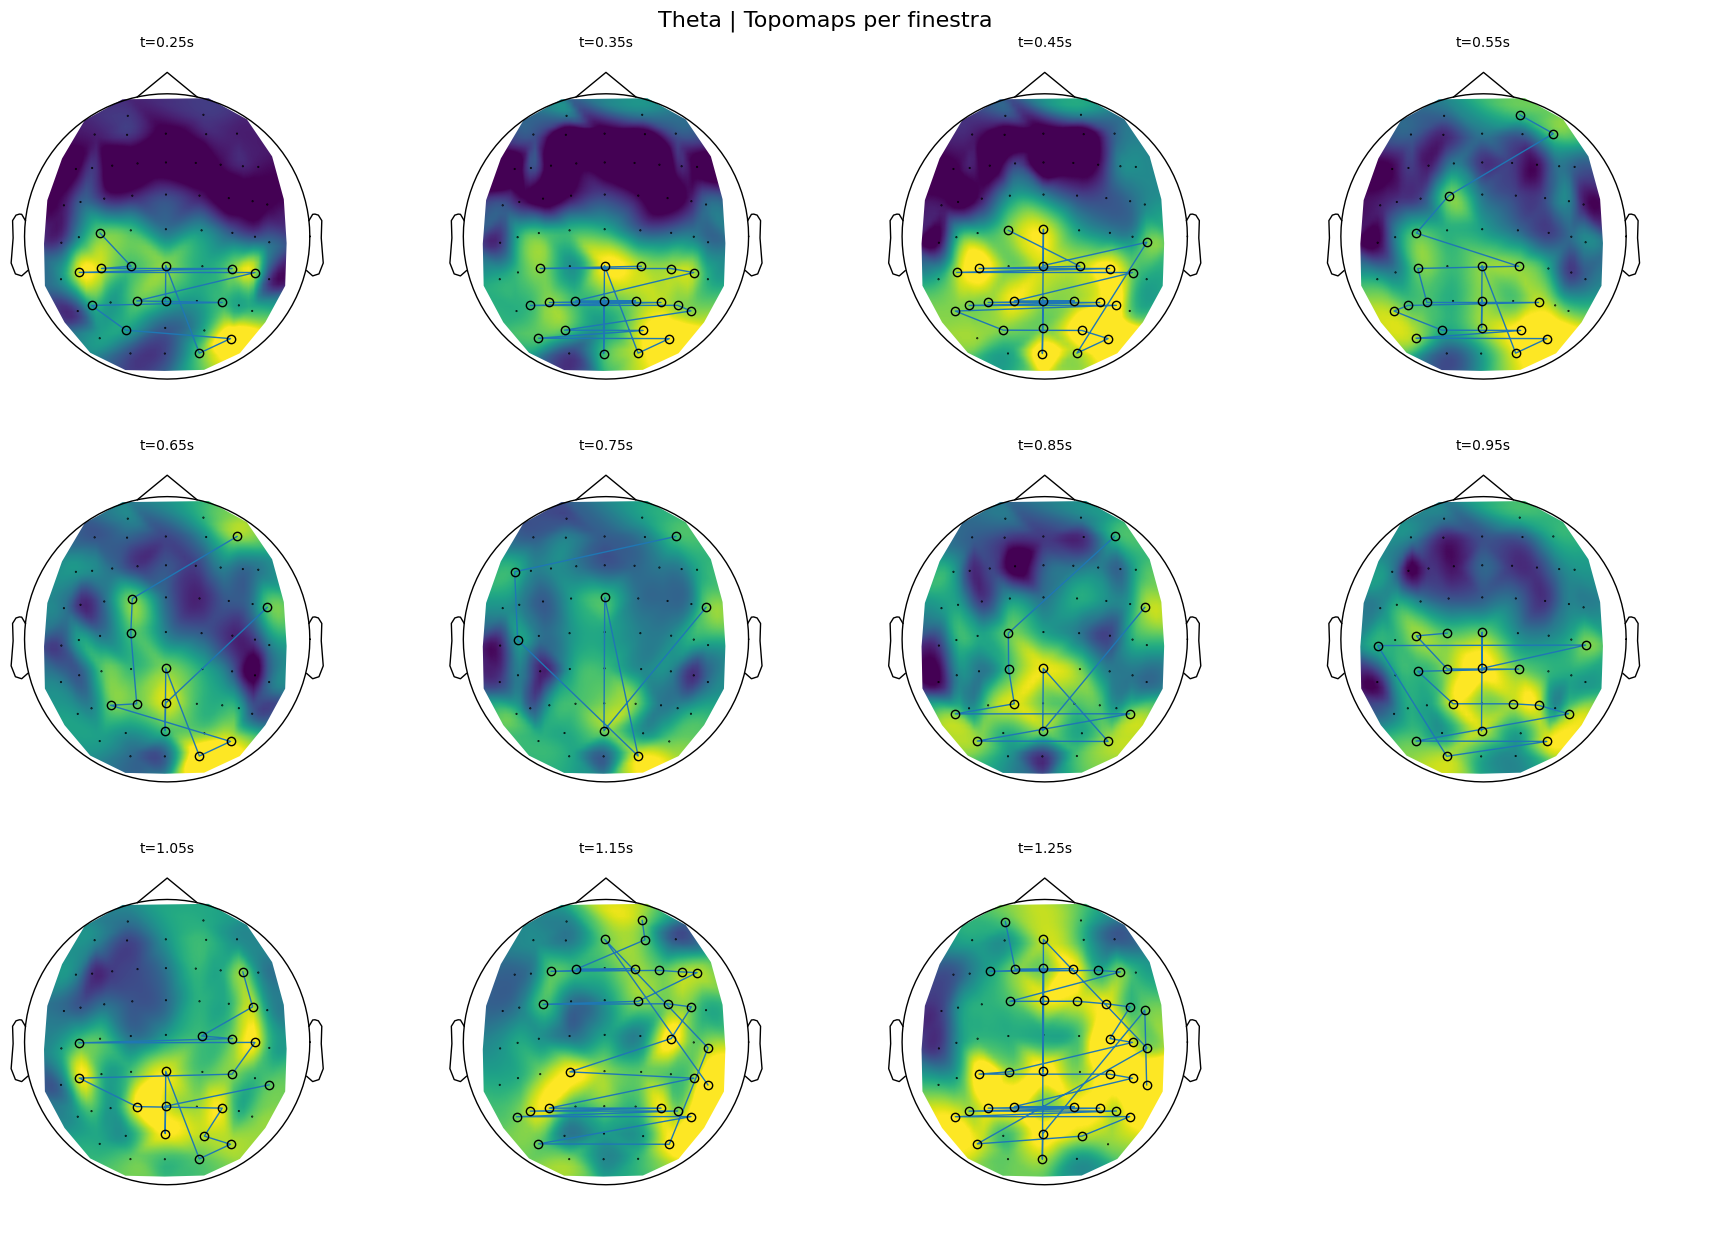

Grid de topomaps (theta) desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\searchlight_theta_topomaps_grid.png
Topomaps (theta) desats a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\topomaps_theta
GIF (theta) desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\searchlight_theta.gif


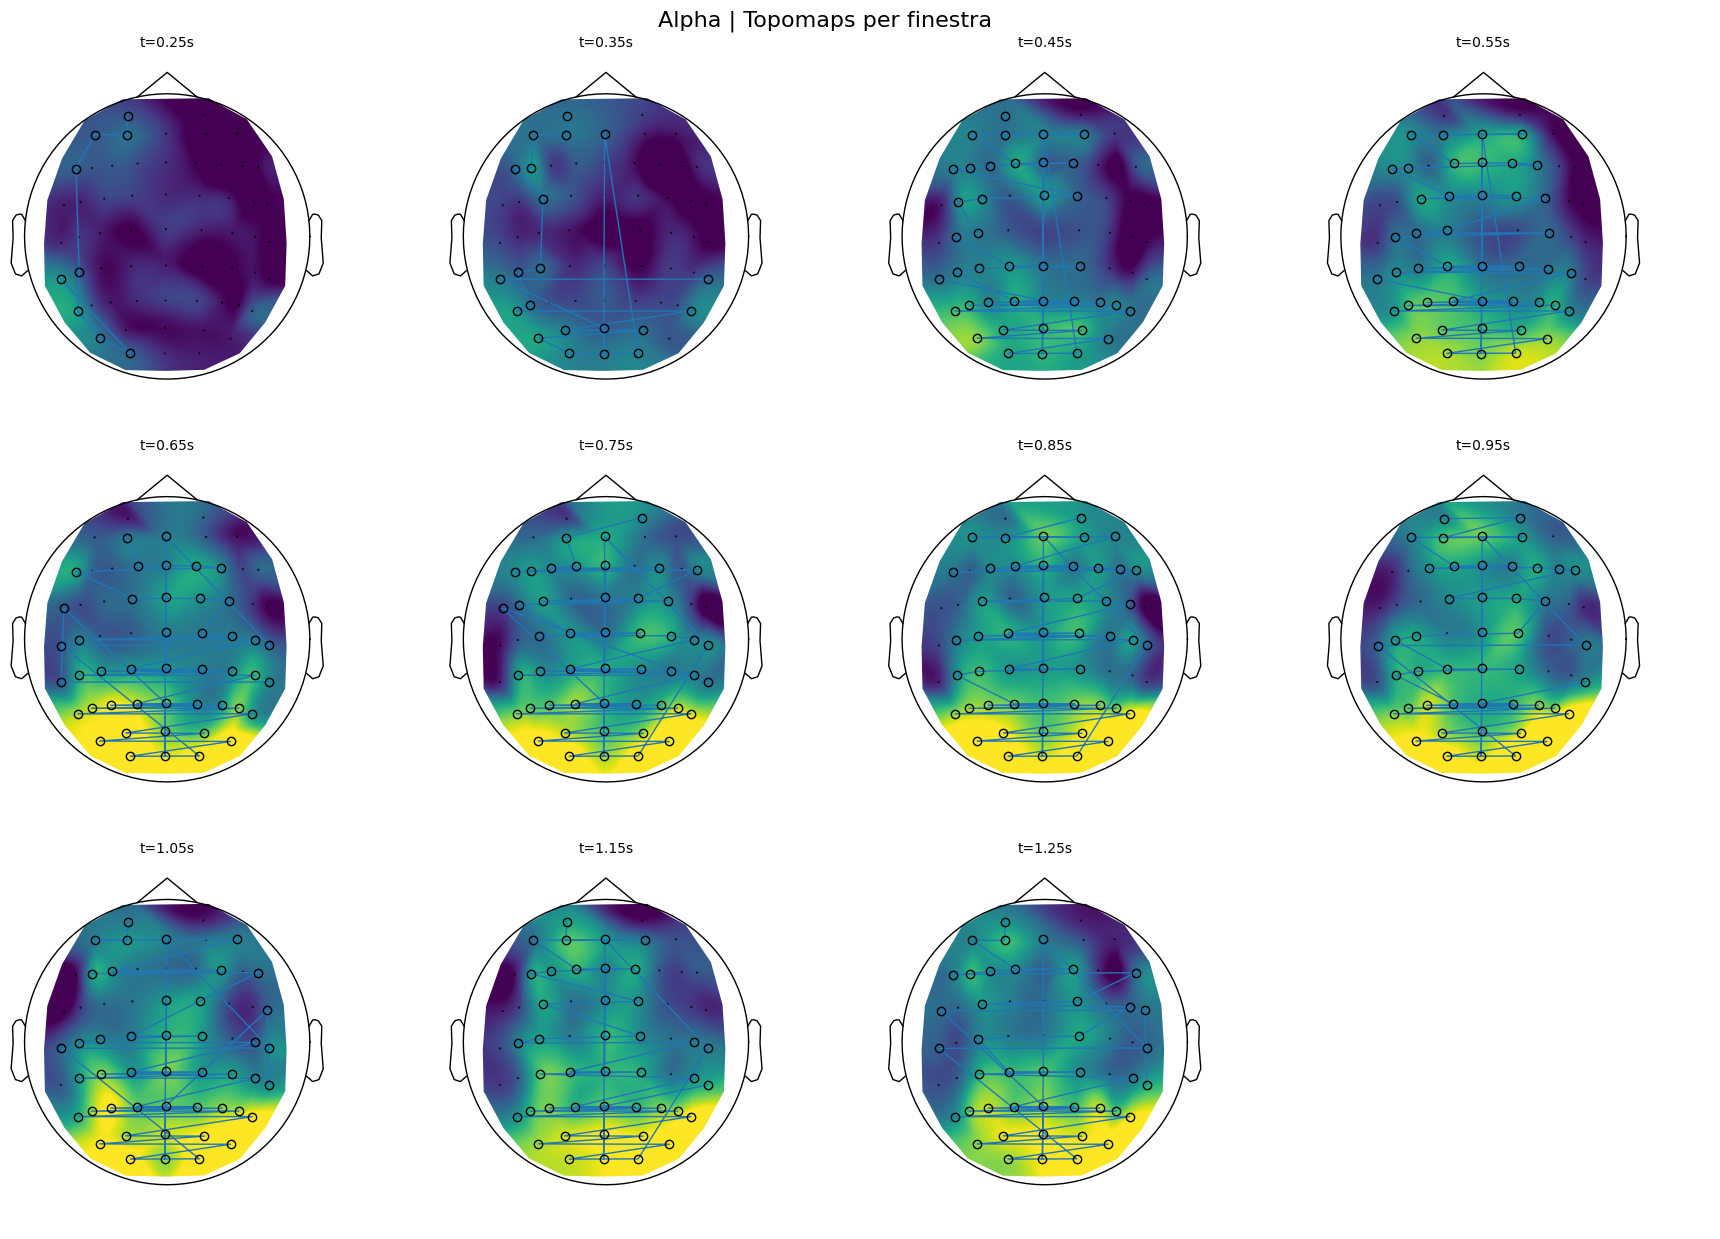

Grid de topomaps (alpha) desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\searchlight_alpha_topomaps_grid.png
Topomaps (alpha) desats a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\topomaps_alpha
GIF (alpha) desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\searchlight_alpha.gif


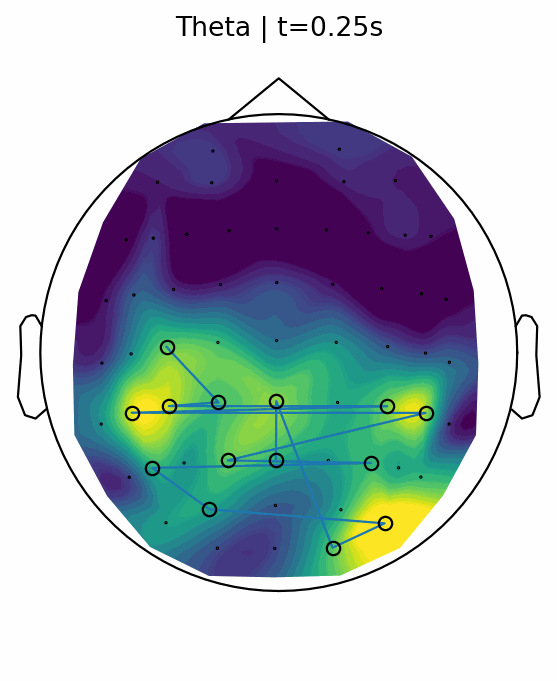

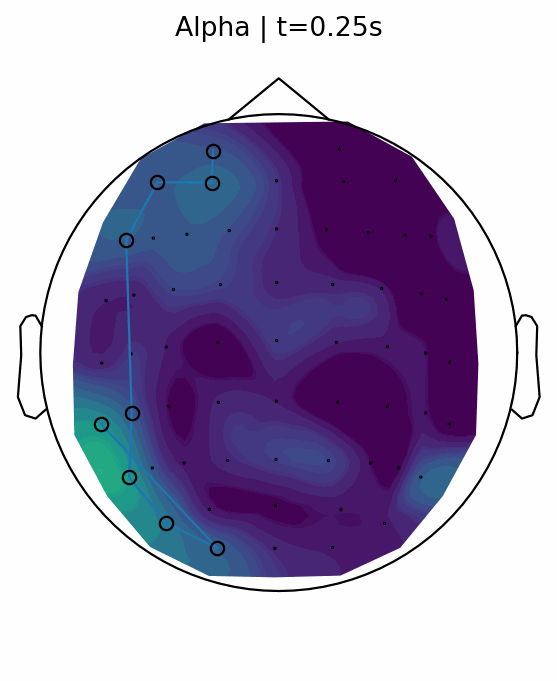

In [9]:
imageio = importlib.import_module("imageio.v2")

for band_name, d in sl_results.items():
    mean_acc = sl_stats[band_name]["mean_acc"]  # C x W
    sig = sl_stats[band_name]["sig"]
    centers = d["window_centers"]

    # Construim info de topomap robusta a cada execucio (independent de l'estat del kernel)
    montage = mne.channels.make_standard_montage("standard_1020")
    available_ch = [ch for ch in d["ch_names"] if ch in montage.ch_names]

    ch_to_idx = {ch: i for i, ch in enumerate(d["ch_names"])}
    keep_idx = [ch_to_idx[ch] for ch in available_ch]

    topo_info = mne.create_info(
        ch_names=available_ch,
        sfreq=float(sl_subjects[0]["epochs"].info["sfreq"]),
        ch_types="eeg",
    )
    topo_info.set_montage(montage, on_missing="raise")

    band_dir = FIGURES_DIR / f"topomaps_{band_name}"
    band_dir.mkdir(parents=True, exist_ok=True)

    mean_acc_keep = mean_acc[keep_idx, :]
    sig_keep = sig[keep_idx, :]

    vmin = float(np.nanpercentile(mean_acc_keep, 5))
    vmax = float(np.nanpercentile(mean_acc_keep, 95))
    frame_paths = []

    for wi in range(mean_acc_keep.shape[1]):
        values = mean_acc_keep[:, wi]
        sig_mask = sig_keep[:, wi]

        fig, ax = plt.subplots(figsize=(5, 5))
        mne.viz.plot_topomap(
            values,
            topo_info,
            axes=ax,
            show=False,
            cmap="viridis",
            vlim=(vmin, vmax),
            contours=0,
            sensors=True,
            mask=sig_mask,
            mask_params={
                "marker": "o",
                "markerfacecolor": "none",
                "markeredgecolor": "black",
                "linewidth": 1.0,
                "markersize": 6,
            },
            sphere=(0.0, 0.02, 0.0, 0.096),
            extrapolate="local",
        )
        ax.set_title(f"{band_name.capitalize()} | t={centers[wi]:.2f}s")

        out_frame = band_dir / f"frame_{wi:02d}.png"
        plt.savefig(out_frame, dpi=160, bbox_inches="tight")
        plt.close(fig)
        frame_paths.append(out_frame)

    gif_path = FIGURES_DIR / f"searchlight_{band_name}.gif"
    images = [imageio.imread(p) for p in frame_paths]
    imageio.mimsave(gif_path, images, duration=0.5, loop=0)

    # Figure amb tots els topomaps en una sola imatge
    n_cols = 4
    n_rows = int(np.ceil(mean_acc_keep.shape[1] / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 4.2 * n_rows))
    axes = np.atleast_1d(axes).ravel()

    for wi in range(mean_acc_keep.shape[1]):
        ax = axes[wi]
        values = mean_acc_keep[:, wi]
        sig_mask = sig_keep[:, wi]

        mne.viz.plot_topomap(
            values,
            topo_info,
            axes=ax,
            show=False,
            cmap="viridis",
            vlim=(vmin, vmax),
            contours=0,
            sensors=True,
            mask=sig_mask,
            mask_params={
                "marker": "o",
                "markerfacecolor": "none",
                "markeredgecolor": "black",
                "linewidth": 1.0,
                "markersize": 6,
            },
            sphere=(0.0, 0.02, 0.0, 0.096),
            extrapolate="local",
        )
        ax.set_title(f"t={centers[wi]:.2f}s", fontsize=10)

    for ax in axes[mean_acc_keep.shape[1] :]:
        ax.axis("off")

    fig.suptitle(f"{band_name.capitalize()} | Topomaps per finestra", fontsize=16)
    plt.tight_layout()

    out_grid = FIGURES_DIR / f"searchlight_{band_name}_topomaps_grid.png"
    plt.savefig(out_grid, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Grid de topomaps ({band_name}) desat a: {out_grid}")

    print(f"Topomaps ({band_name}) desats a: {band_dir}")
    print(f"GIF ({band_name}) desat a: {gif_path}")

for band_name in BANDS.keys():
    display(Image(filename=str(FIGURES_DIR / f"searchlight_{band_name}.gif")))

## 8. En quins moments i en quines zones del cap domina més la banda Alfa que la Theta (o a l'inrevés) per discriminar C vs IP?

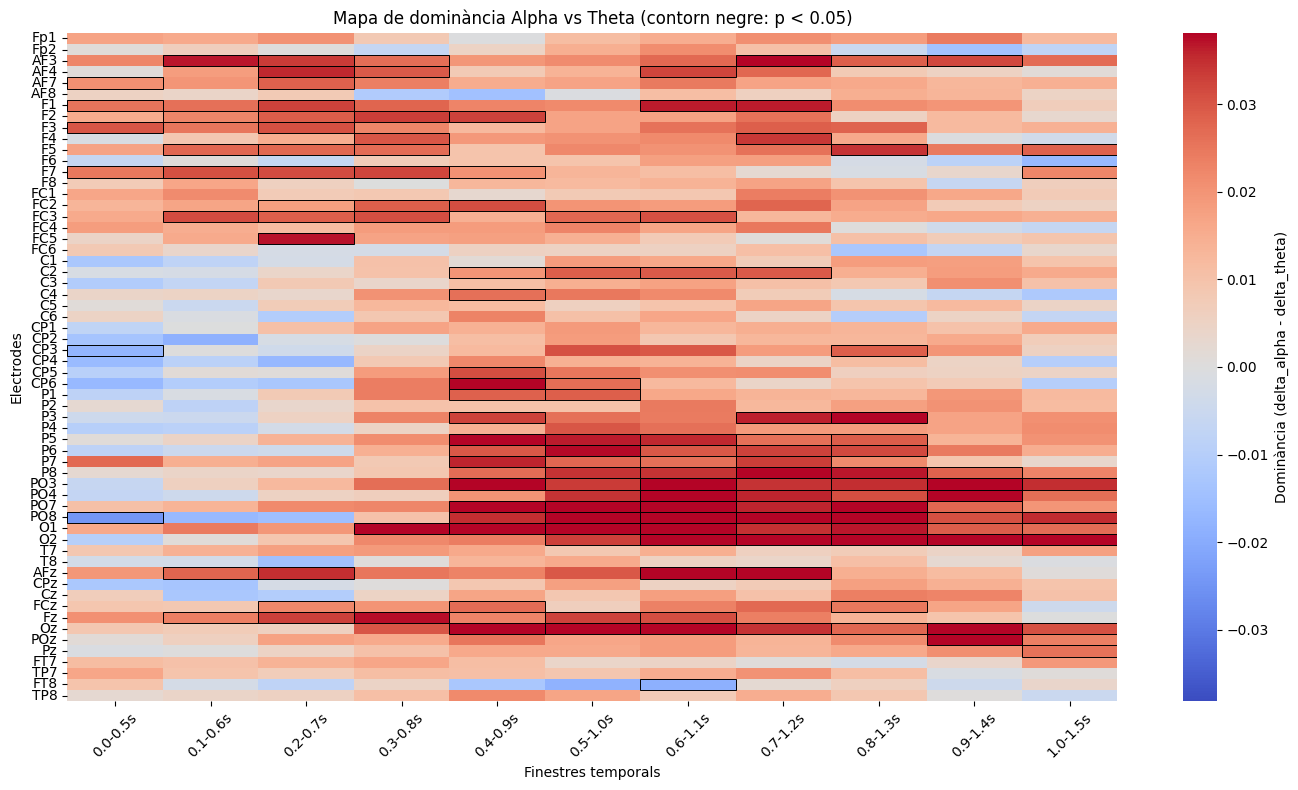

Desat heatmap: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\searchlight_alpha_vs_theta_dominance_heatmap.png


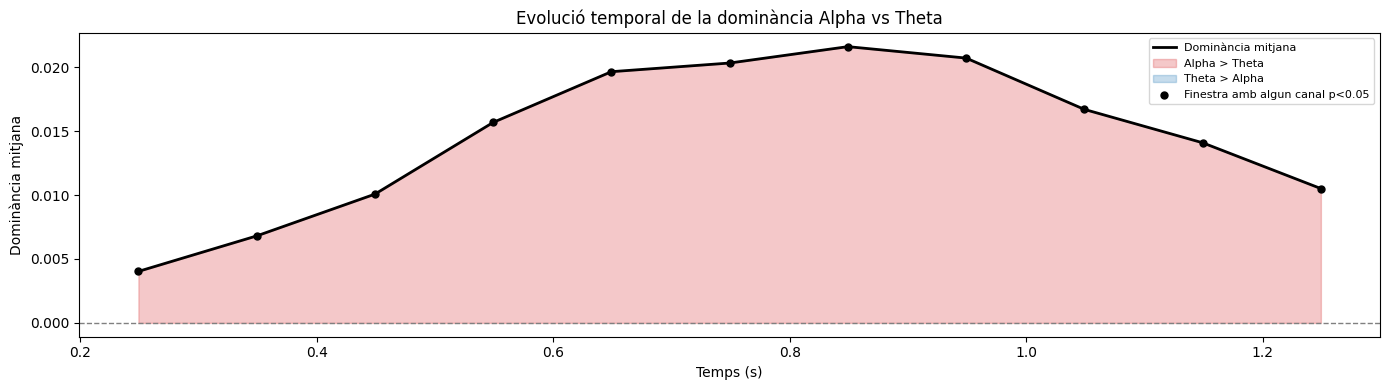

Desat corba: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\searchlight_alpha_vs_theta_dominance_curve.png


In [10]:
if not ({"alpha", "theta"} <= set(sl_stats.keys())):
    print("Cal tenir resultats de les bandes alpha i theta per aquesta visualització.")
else:
    alpha_delta = sl_stats["alpha"]["delta_acc"]
    theta_delta = sl_stats["theta"]["delta_acc"]
    dominance = alpha_delta - theta_delta  # >0: domina alpha, <0: domina theta

    alpha_acc = sl_results["alpha"]["acc"]  # S x C x W
    theta_acc = sl_results["theta"]["acc"]
    diff_subj = alpha_acc - theta_acc
    _, p_dom = ttest_1samp(diff_subj, popmean=0.0, axis=0, nan_policy="omit", alternative="two-sided")
    sig_dom = p_dom < 0.05

    win_labels = sl_results["alpha"]["window_labels"]
    ch_names = sl_results["alpha"]["ch_names"]
    centers = sl_results["alpha"]["window_centers"]

    # Plot 1: heatmap de dominancia
    fig, ax = plt.subplots(figsize=(14, 8))
    vmax = float(np.nanpercentile(np.abs(dominance), 95))
    sns.heatmap(
        dominance,
        ax=ax,
        cmap="coolwarm",
        center=0.0,
        vmin=-vmax,
        vmax=vmax,
        xticklabels=win_labels,
        yticklabels=ch_names,
        cbar_kws={"label": "Dominància (delta_alpha - delta_theta)"},
    )

    for i in range(dominance.shape[0]):
        for j in range(dominance.shape[1]):
            if sig_dom[i, j]:
                ax.add_patch(patches.Rectangle((j, i), 1, 1, fill=False, edgecolor="black", linewidth=0.7))

    ax.set_title("Mapa de dominància Alpha vs Theta (contorn negre: p < 0.05)")
    ax.set_xlabel("Finestres temporals")
    ax.set_ylabel("Electrodes")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()

    out_dom_heat = FIGURES_DIR / "searchlight_alpha_vs_theta_dominance_heatmap.png"
    plt.savefig(out_dom_heat, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Desat heatmap: {out_dom_heat}")

    # Plot 2: corba temporal de dominancia
    fig, ax = plt.subplots(figsize=(14, 4))
    dom_mean_t = np.nanmean(dominance, axis=0)
    sig_t = np.any(sig_dom, axis=0)

    ax.plot(centers, dom_mean_t, color="black", linewidth=2, label="Dominància mitjana")
    ax.fill_between(centers, 0, dom_mean_t, where=dom_mean_t >= 0, color="tab:red", alpha=0.25, label="Alpha > Theta")
    ax.fill_between(centers, 0, dom_mean_t, where=dom_mean_t < 0, color="tab:blue", alpha=0.25, label="Theta > Alpha")
    ax.scatter(
        centers[sig_t], dom_mean_t[sig_t], color="black", s=25, zorder=3, label="Finestra amb algun canal p<0.05"
    )
    ax.axhline(0.0, color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel("Temps (s)")
    ax.set_ylabel("Dominància mitjana")
    ax.set_title("Evolució temporal de la dominància Alpha vs Theta")
    ax.legend(loc="best", fontsize=8)
    plt.tight_layout()

    out_dom_curve = FIGURES_DIR / "searchlight_alpha_vs_theta_dominance_curve.png"
    plt.savefig(out_dom_curve, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Desat corba: {out_dom_curve}")

## 9. Matriu de Generalització Temporal (TGM)

En aquest pas la idea és entrenar models en una part del trial (ex: 300ms) i fer el test a una altra (ex: 600ms) per veure si el patró perdura en el temps. Si el rendiment es manté elevat, vol dir que hi ha patrons similars en els dos instants de temps.

El problema és que les matrius tenen una dimensió gegant de fins a 22 milions de cel·les (496 mostres × 60 elèctrodes × 751 finestres). Però això és amb un mostreig de 500 Hz. Segons el teorema de Nyquist, necessitem com a mínim el doble de la freqüència màxima d'interès per capturar els patrons. Com que estem interessats en Theta (4-8 Hz) i Alfa (8-12 Hz), 24 Hz és el límit inferior teòric, i el duplico per tenir un marge de seguretat, arribant a 48 Hz. Per tant, es podria reduir el mostreig a 50 Hz sense perdre informació rellevant, cosa que reduiria dràsticament la dimensió de les matrius i faria el càlcul més manejable.

TGM carregada de caché: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\cache\cache_tgm_minim.npz


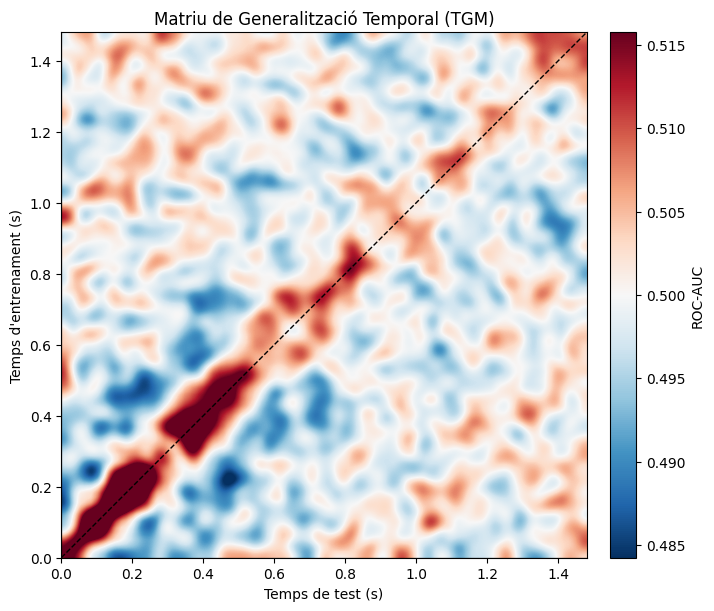

In [11]:
cache_tgm = CACHE_DIR / "cache_tgm_minim.npz"
subjectes_actuals = np.array([s["subject"] for s in sl_subjects], dtype=str)

try:
    z = np.load(cache_tgm, allow_pickle=False)
    tgm_tensor_cache = z["tgm_tensor"]
    times_tgm_cache = z["times_tgm"]
    subjectes_cache = z["subjectes"]

    # Reutilitzem només si la llista de subjectes coincideix exactament.
    if np.array_equal(subjectes_cache.astype(str), subjectes_actuals):
        tgm_tensor = tgm_tensor_cache
        times_tgm = times_tgm_cache
        print(f"TGM carregada de caché: {cache_tgm}")
    else:
        print("Caché TGM ignorada: subjectes diferents. Es recalcula.")

except FileNotFoundError as e:
    print(f"No s'ha pogut carregar la caché ({type(e).__name__}). Es recalcula.")

    tgm_scores_all = []
    for s in sl_subjects:
        # Reducció de mostreig per reduir cost computacional.
        ep_tgm = s["epochs"].copy().load_data()
        ep_tgm._data = np.array(ep_tgm.get_data(), copy=True, order="C")
        ep_tgm.filter(l_freq=None, h_freq=30.0, method="fir", phase="zero-double", verbose=False)
        ep_tgm = ep_tgm.resample(50, npad="auto", verbose=False)

        X_tgm = ep_tgm.get_data()
        y_tgm = s["y"]

        clf_tgm = make_pipeline(StandardScaler(), LogisticRegression(solver="liblinear", tol=1e-3))
        time_gen = GeneralizingEstimator(clf_tgm, scoring="roc_auc", verbose=False)

        # 3-fold CV per subjecte.
        scores = cross_val_multiscore(time_gen, X_tgm, y_tgm, cv=3, n_jobs=N_JOBS)
        tgm_scores_all.append(np.mean(scores, axis=0))

    tgm_tensor = np.stack(tgm_scores_all, axis=0)  # (subjectes, train_t, test_t)
    times_tgm = sl_subjects[0]["epochs"].copy().decimate(10).times

    # Guardem només el mínim necessari per no repetir càlcul pesat.
    np.savez_compressed(
        cache_tgm,
        tgm_tensor=tgm_tensor,
        times_tgm=times_tgm,
        subjectes=subjectes_actuals,
    )
    print(f"TGM desada a caché: {cache_tgm}")

# Compatibilitat amb cel·les anteriors.
tgm_scores_all = [tgm_tensor[i] for i in range(tgm_tensor.shape[0])]
tgm_ga = np.mean(tgm_tensor, axis=0)

# Matriu TGM global
n_t = min(tgm_tensor.shape[1], len(times_tgm))
times = np.asarray(times_tgm)[:n_t]
tgm_tensor_use = tgm_tensor[:, :n_t, :n_t]

# Significació per separar p<0.05 i p>0.05.
_, p_vals = ttest_1samp(tgm_tensor_use, popmean=0.5, axis=0, alternative="greater")
sig_mask = p_vals < 0.05

tgm_ga = np.mean(tgm_tensor_use, axis=0)
tgm_ga_smooth = gaussian_filter(tgm_ga, sigma=1.0)

fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)

vmax_real = float(np.percentile(tgm_ga_smooth, 98))
vmin_real = 0.5 - (vmax_real - 0.5)

im = ax.imshow(
    tgm_ga_smooth,
    interpolation="lanczos",
    origin="lower",
    cmap="RdBu_r",
    extent=[times[0], times[-1], times[0], times[-1]],
    vmin=vmin_real,
    vmax=vmax_real,
)

ax.axhline(0.0, color="k", linestyle="-", linewidth=1, alpha=0.5)
ax.axvline(0.0, color="k", linestyle="-", linewidth=1, alpha=0.5)
ax.plot([times[0], times[-1]], [times[0], times[-1]], color="k", linestyle="--", linewidth=1)

ax.set_xlabel("Temps de test (s)")
ax.set_ylabel("Temps d'entrenament (s)")
ax.set_title("Matriu de Generalització Temporal (TGM)")

cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("ROC-AUC")

out_tgm_matrix = FIGURES_DIR / "tgm_matrix_only.png"
plt.savefig(out_tgm_matrix, dpi=300, bbox_inches="tight")
plt.show()

## 10. Mapes de Latència

Aquí volem veure quina àrea del cervell és la primera en poder classificar C-IP de manera significativa. Es fa amb un t-test d'una mostra contra 0.5 per cada elèctrode i finestra, i es dibuixa un topomap on el color indica la latència d'onset (primer instant de temps amb acc > 0.5 significatiu).

[theta] strict onset: 54 | relaxed onset: 6


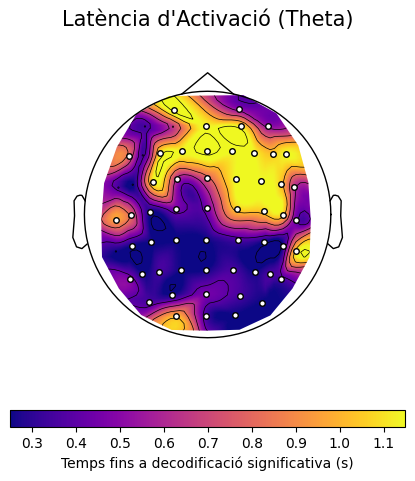

Onset theta desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\onset_map_theta.png
[alpha] strict onset: 60 | relaxed onset: 0


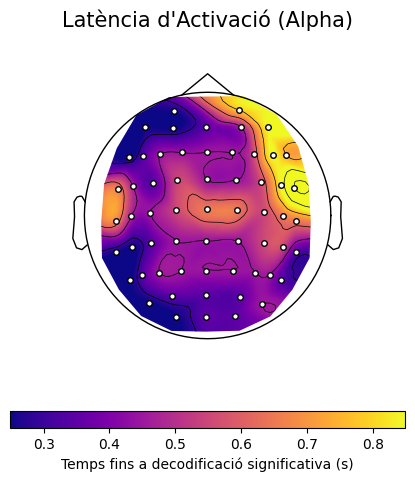

Onset alpha desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\onset_map_alpha.png


In [12]:
def sl_prepare_onset_topo(result_dict, sfreq):
    """Create a stable topomap info aligned with result channels."""
    montage = mne.channels.make_standard_montage("standard_1020")
    ch_names = result_dict["ch_names"]

    available_ch = [ch for ch in ch_names if ch in montage.ch_names]
    if len(available_ch) < 4:
        raise RuntimeError("No hi ha prou canals amb posicio valida al montage standard_1020.")

    ch_to_idx = {ch: i for i, ch in enumerate(ch_names)}
    keep_idx = [ch_to_idx[ch] for ch in available_ch]

    topo_info = mne.create_info(
        ch_names=available_ch,
        sfreq=float(sfreq),
        ch_types="eeg",
    )
    topo_info.set_montage(montage, on_missing="raise")
    return topo_info, keep_idx


def plot_onset_map(accuracy_matrix, times, topo_info, keep_idx, band_name, out_dir):
    # Keep only channels with known montage coordinates to avoid misplaced sensors.
    acc = accuracy_matrix[:, keep_idx, :]
    n_electrodes = acc.shape[1]
    onset_times = np.full(n_electrodes, np.nan, dtype=float)
    sig_ch = np.zeros(n_electrodes, dtype=bool)
    n_strict, n_relaxed = 0, 0

    for ch_idx in range(n_electrodes):
        _, p_vals = ttest_1samp(
            acc[:, ch_idx, :],
            popmean=0.5,
            axis=0,
            nan_policy="omit",
            alternative="greater",
        )
        mean_acc_time = np.nanmean(acc[:, ch_idx, :], axis=0)

        # Strict onset: first statistically significant timepoint above chance.
        strict_idx = np.where((p_vals < 0.05) & (mean_acc_time > 0.5))[0]
        if len(strict_idx) > 0:
            onset_times[ch_idx] = float(times[strict_idx[0]])
            sig_ch[ch_idx] = True
            n_strict += 1
            continue

        # Relaxed onset: first crossing above chance.
        relaxed_idx = np.where(mean_acc_time > 0.5)[0]
        if len(relaxed_idx) > 0:
            onset_times[ch_idx] = float(times[relaxed_idx[0]])
            n_relaxed += 1
            continue

    mask_invalid = np.isnan(onset_times)
    if np.all(mask_invalid):
        print(f"[{band_name}] Sense onsets valids; no es pot dibuixar el mapa.")
        return

    finite_vals = onset_times[~mask_invalid]
    if finite_vals.size > 1:
        vmin = float(np.nanpercentile(finite_vals, 5))
        vmax = float(np.nanpercentile(finite_vals, 95))
    else:
        vmin = float(finite_vals[0] - 0.05)
        vmax = float(finite_vals[0] + 0.05)
    if vmax <= vmin:
        vmax = vmin + 1e-3

    # Impute missing channels for interpolation only, to avoid blank maps.
    onset_plot = onset_times.copy()
    if np.any(mask_invalid):
        onset_plot[mask_invalid] = float(np.nanmedian(finite_vals))

    fig = plt.figure(figsize=(5.1, 4.8))
    gs = fig.add_gridspec(nrows=2, ncols=1, height_ratios=[18, 1], hspace=0.2)
    ax = fig.add_subplot(gs[0, 0])
    cax = fig.add_subplot(gs[1, 0])

    im, _ = mne.viz.plot_topomap(
        onset_plot,
        topo_info,
        axes=ax,
        cmap="plasma",
        vlim=(vmin, vmax),
        mask=sig_ch,
        mask_params={
            "marker": "o",
            "markerfacecolor": "white",
            "markeredgecolor": "black",
            "linewidth": 0.0,
            "markersize": 4,
        },
        contours=6,
        sensors=True,
        extrapolate="local",
        sphere=(0.0, 0.02, 0.0, 0.096),
        show=False,
    )
    ax.set_aspect("equal", adjustable="box")

    ax.set_title(f"Latència d'Activació ({band_name.capitalize()})\n", fontsize=15)
    cbar = fig.colorbar(im, cax=cax, orientation="horizontal")
    cbar.set_label("Temps fins a decodificació significativa (s)")

    print(f"[{band_name}] strict onset: {n_strict} | relaxed onset: {n_relaxed}")

    out_onset = out_dir / f"onset_map_{band_name}.png"
    plt.savefig(out_onset, dpi=300, bbox_inches="tight", pad_inches=0.05)
    plt.show()
    print(f"Onset {band_name} desat a: {out_onset}")


sfreq_ref = float(sl_subjects[0]["epochs"].info["sfreq"])
for band_name, d in sl_results.items():
    topo_info, keep_idx = sl_prepare_onset_topo(d, sfreq_ref)
    plot_onset_map(d["acc"], d["window_centers"], topo_info, keep_idx, band_name, FIGURES_DIR)

## 11. Correlacions en funció de la distància entre elèctrodes


Processant subjecte: P057
Utilitzant 1770 parells d'elèctrodes.


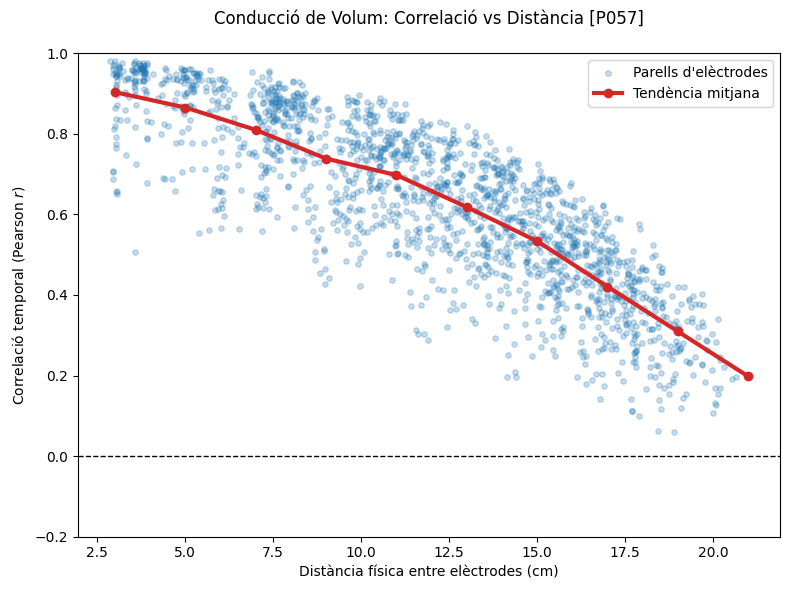

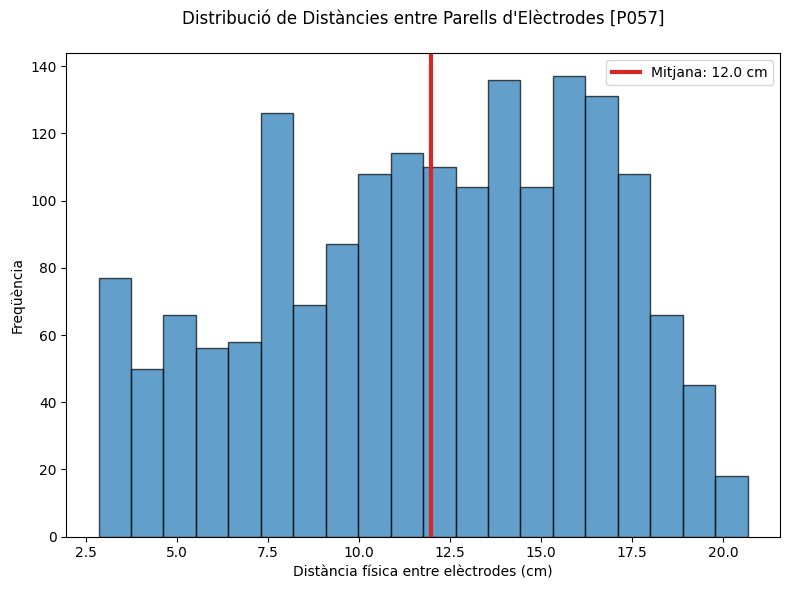

Utilitzant 38940 parells d'elèctrodes.


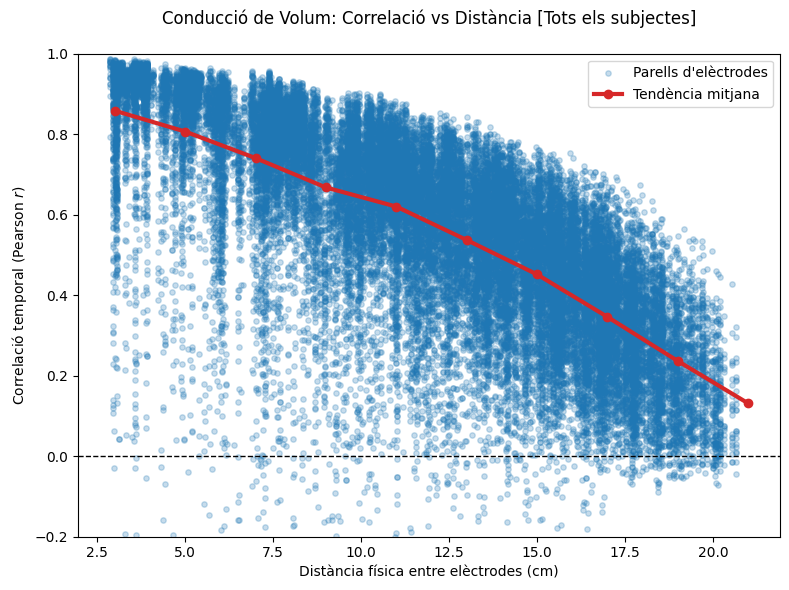

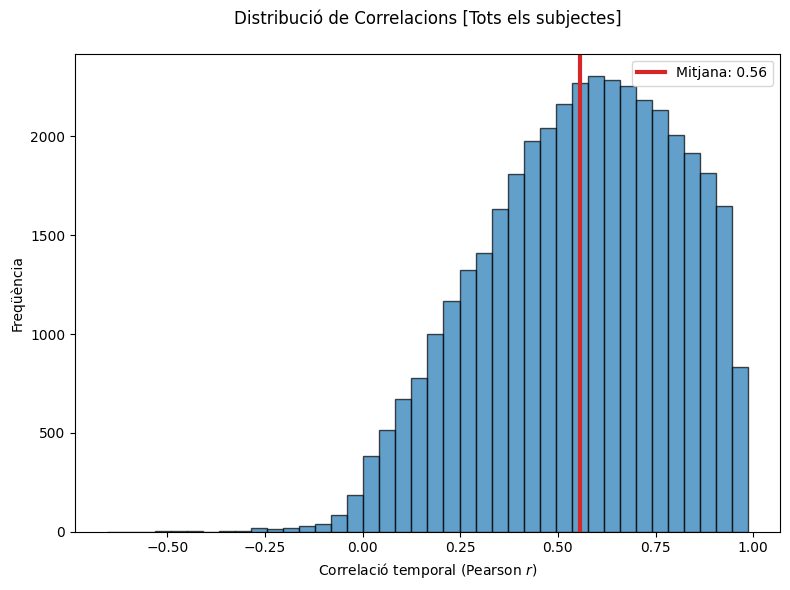

In [13]:
def grafic_caiguda_correlacio_espacial(epochs, titol_extra="", es_inter=False):
    """
    Calcula i visualitza la correlació espacial vs distància entre elèctrodes.

    Parameters:
    -----------
    epochs : mne.Epochs o list de mne.Epochs
        Si es_inter=False: un únic objecte Epochs (intra-subjecte)
        Si es_inter=True: llista de múltiples Epochs (inter-subjecte)
    titol_extra : str
        Text extra pel títol
    es_inter : bool
        Si True, combina dades de múltiples subjectes (inter)
        Si False, analitza un sol subjecte (intra)
    """

    if es_inter and isinstance(epochs, list):
        # ============= MODE INTER-SUBJECTE =============
        # Combina dades de tots els subjectes
        all_distancies = []
        all_correlacions = []

        for ep_subj in epochs:
            ep_temp = ep_subj.copy()
            muntatge = mne.channels.make_standard_montage("standard_1005")
            ep_temp.set_montage(muntatge, match_case=False, on_missing="ignore")

            posicions = np.array([ch["loc"][:3] for ch in ep_temp.info["chs"]]) * 100
            mascara_valids = np.any(posicions != 0, axis=1)
            posicions_valides = posicions[mascara_valids]

            if np.sum(mascara_valids) < 4:
                continue

            dist_mat = squareform(pdist(posicions_valides))
            dades = ep_temp.get_data()[:, mascara_valids, :].transpose(1, 0, 2).reshape(np.sum(mascara_valids), -1)
            corr_mat = np.corrcoef(dades)

            triu_idx = np.triu_indices_from(dist_mat, k=1)
            all_distancies.append(dist_mat[triu_idx])
            all_correlacions.append(corr_mat[triu_idx])

        # Combina tots els parells de tots els subjectes
        distancies_parells = np.concatenate(all_distancies)
        correlacions_parells = np.concatenate(all_correlacions)

    else:
        # ============= MODE INTRA-SUBJECTE =============
        ep_temp = epochs.copy()
        muntatge = mne.channels.make_standard_montage("standard_1005")
        ep_temp.set_montage(muntatge, match_case=False, on_missing="ignore")

        posicions = np.array([ch["loc"][:3] for ch in ep_temp.info["chs"]]) * 100
        mascara_valids = np.any(posicions != 0, axis=1)
        posicions_valides = posicions[mascara_valids]

        dist_mat = squareform(pdist(posicions_valides))
        dades = ep_temp.get_data()[:, mascara_valids, :].transpose(1, 0, 2).reshape(np.sum(mascara_valids), -1)
        corr_mat = np.corrcoef(dades)

        triu_idx = np.triu_indices_from(dist_mat, k=1)
        distancies_parells = dist_mat[triu_idx]
        correlacions_parells = corr_mat[triu_idx]

    print(f"Utilitzant {len(distancies_parells)} parells d'elèctrodes.")

    # ---------------------------------------------------------
    # CÀLCUL DE ESTADÍSTIQUES PER BINS
    # ---------------------------------------------------------
    intervals = np.arange(0, distancies_parells.max() + 2, 2)
    centres_intervals = (intervals[:-1] + intervals[1:]) / 2
    mitjanes_corr = []

    for i in range(len(intervals) - 1):
        mascara_bin = (distancies_parells >= intervals[i]) & (distancies_parells < intervals[i + 1])
        if np.any(mascara_bin):
            vals = correlacions_parells[mascara_bin]
            mitjanes_corr.append(np.mean(vals))
        else:
            mitjanes_corr.append(np.nan)

    mitjanes_corr = np.array(mitjanes_corr)

    mode_text = "Tots els subjectes" if es_inter else f"{titol_extra}"

    # ---------------------------------------------------------
    # FIGURA 1: SCATTER + TOBOGAN
    # ---------------------------------------------------------
    fig1, ax1 = plt.subplots(figsize=(8, 6))
    ax1.scatter(
        distancies_parells, correlacions_parells, alpha=0.25, color="tab:blue", s=15, label="Parells d'elèctrodes"
    )
    ax1.plot(centres_intervals, mitjanes_corr, color="tab:red", linewidth=3, marker="o", label="Tendència mitjana")
    ax1.axhline(0, color="black", linestyle="--", linewidth=1)
    ax1.set_title(f"Conducció de Volum: Correlació vs Distància [{mode_text}]\n")
    ax1.set_xlabel("Distància física entre elèctrodes (cm)")
    ax1.set_ylabel("Correlació temporal (Pearson $r$)")
    ax1.set_ylim(-0.2, 1.0)
    ax1.legend()
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"correlacio_espacial_scatter{titol_extra}.png", dpi=180, bbox_inches="tight")
    plt.show()

    # ---------------------------------------------------------
    # FIGURA 2: HISTOGRAMA (només per inter-subjecte)
    # ---------------------------------------------------------
    if es_inter:
        fig2, ax2 = plt.subplots(figsize=(8, 6))
        ax2.hist(correlacions_parells, bins=40, color="tab:blue", alpha=0.7, edgecolor="black")
        ax2.axvline(
            np.mean(correlacions_parells),
            color="tab:red",
            linewidth=3,
            label=f"Mitjana: {np.mean(correlacions_parells):.2f}",
        )
        ax2.set_title(f"Distribució de Correlacions [{mode_text}]\n")
        ax2.set_xlabel("Correlació temporal (Pearson $r$)")
        ax2.set_ylabel("Freqüència")
        ax2.legend()
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / f"correlacio_espacial_histograma.png", dpi=180, bbox_inches="tight")
        plt.show()
    else:
        # Histograma de distàncies entre parelles d'elèctrodes
        fig2, ax2 = plt.subplots(figsize=(8, 6))
        ax2.hist(distancies_parells, bins=20, color="tab:blue", alpha=0.7, edgecolor="black")
        ax2.axvline(
            np.mean(distancies_parells),
            color="tab:red",
            linewidth=3,
            label=f"Mitjana: {np.mean(distancies_parells):.1f} cm",
        )
        ax2.set_title(f"Distribució de Distàncies entre Parells d'Elèctrodes [{mode_text}]\n")
        ax2.set_xlabel("Distància física entre elèctrodes (cm)")
        ax2.set_ylabel("Freqüència")
        ax2.legend()
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / f"correlacio_espacial_histograma_distancies.png", dpi=180, bbox_inches="tight")
        plt.show()


subj_data = sl_subjects[0]
subj_name = subj_data["subject"]
ep_subj = subj_data["epochs"]
print(f"\nProcessant subjecte: {subj_name}")
grafic_caiguda_correlacio_espacial(ep_subj, titol_extra=subj_name, es_inter=False)

epochs_list = [s["epochs"] for s in sl_subjects]
grafic_caiguda_correlacio_espacial(epochs_list, titol_extra="", es_inter=True)

## 12. Espectrograma de Classificació
**L'Explicació Tècnica:** S'utilitza una transformació d'onetes (Morlet wavelets) per explorar contínuament la potència entre 4Hz i 30Hz, aplicant una correcció tipus *logratio* segons la línia base abans de l'estímul. Aquest plot permet desglosar detingudament les oscil·lacions de cada banda freqüencial, visualitzat sobre l'elèctrode central `FCz` en 1 sol subjecte.
*(⭐ Forma d'estendre-ho fàcilment: Convertir això en una mitjana inter-subjecte combinant les estructures TFR de tothom trauria el soroll arbitrari particular i ens permetria assenyalar patrons d'interès poblacionals clars en TFR o ampliar-se a varis elèctrodes parietals)*

**En llenguatge més planer:** Imagina que el cervell és com una gran orquestra. Aquest gràfic seria la gran partitura que ens deixa veure en quin precís segon certs grups d'instruments com els "Tubes" (banda Theta) o els "Violins" (banda Alpha) pugen o baixen de volum musical bruscament. Ens dona un "codi de barres" visual, o una empremta, de l'estrès intern de quan t'enfrontes al subjecte de conflicte.

Millor subjecte detectat: P057 (Accuracy mitjana: 0.588)


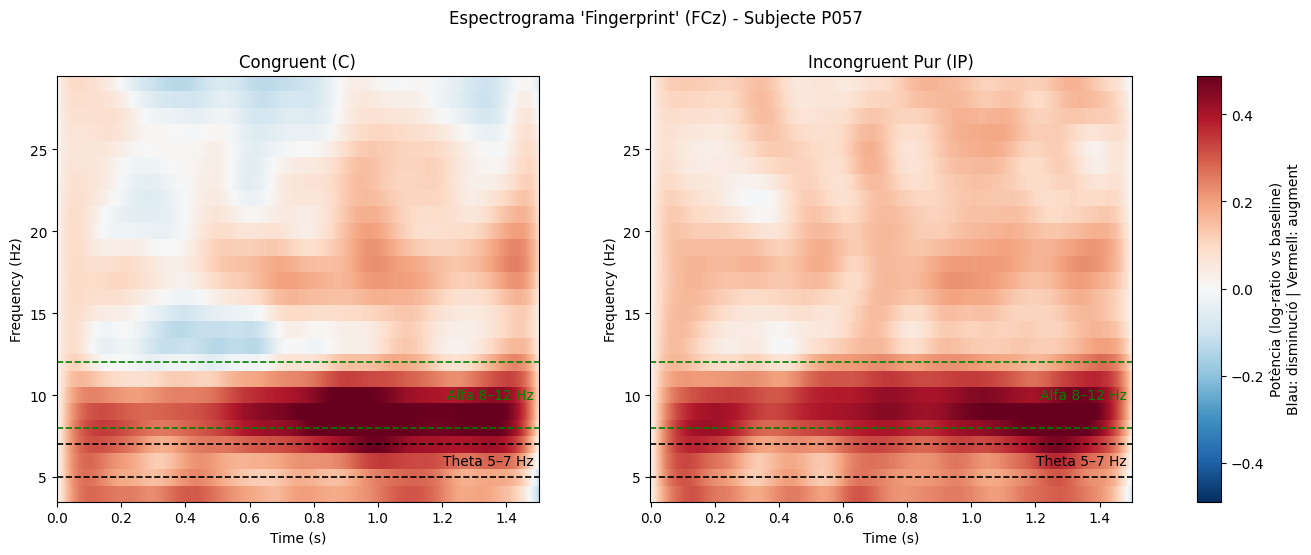

In [14]:
# 1. Trobem el subjecte amb millor accuracy general a la banda Theta
theta_acc = sl_results["theta"]["acc"]  # Shape: (S, C, W)
subj_mean_acc = np.mean(theta_acc, axis=(1, 2))
best_subj_idx = int(np.argmax(subj_mean_acc))
best_subj_data = sl_subjects[best_subj_idx]
best_subj_name = best_subj_data["subject"]

print(f"Millor subjecte detectat: {best_subj_name} (Accuracy mitjana: {subj_mean_acc[best_subj_idx]:.3f})")

ep_best = best_subj_data["epochs"]
y_best = best_subj_data["y"]

# Separem les classes utilitzant la variable y
ep_c = ep_best[y_best == 0]
ep_ip = ep_best[y_best == 1]

# Calculem TFR (Morlet Wavelets) de 4Hz a 30Hz
freqs = np.arange(4, 30, 1)
n_cycles = freqs / 2.0

tfr_c = mne.time_frequency.tfr_morlet(ep_c, freqs=freqs, n_cycles=n_cycles, return_itc=False, average=True)
tfr_ip = mne.time_frequency.tfr_morlet(ep_ip, freqs=freqs, n_cycles=n_cycles, return_itc=False, average=True)

# Baseline (logratio)
tfr_c.apply_baseline(baseline=(0, 0), mode="logratio")
tfr_ip.apply_baseline(baseline=(0, 0), mode="logratio")

# Layout amb eix dedicat per colorbar a la dreta
fig = plt.figure(figsize=(13, 5), constrained_layout=True)
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.05], wspace=0.15)
ax_c = fig.add_subplot(gs[0, 0])
ax_ip = fig.add_subplot(gs[0, 1], sharex=ax_c, sharey=ax_c)
cax = fig.add_subplot(gs[0, 2])

cmax = max(np.max(np.abs(tfr_c.data)), np.max(np.abs(tfr_ip.data))) * 0.7
vlim = (-cmax, cmax)

tfr_c.plot("FCz", axes=ax_c, show=False, colorbar=False, cmap="RdBu_r", vlim=vlim)
ax_c.set_title("Congruent (C)")

tfr_ip.plot("FCz", axes=ax_ip, show=False, colorbar=False, cmap="RdBu_r", vlim=vlim)
ax_ip.set_title("Incongruent Pur (IP)")

# Marques de bandes sense omplir: línies horitzontals
for ax in (ax_c, ax_ip):
    # Theta: 5 i 7 Hz
    ax.axhline(5, color="black", linestyle="--", linewidth=1.2)
    ax.axhline(7, color="black", linestyle="--", linewidth=1.2)

    # Alfa: 8 i 12 Hz
    ax.axhline(8, color="green", linestyle="--", linewidth=1.2)
    ax.axhline(12, color="green", linestyle="--", linewidth=1.2)

    # Etiquetes
    ax.text(
        0.99,
        6,
        "Theta 5–7 Hz",
        transform=ax.get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=10,
        color="black",
    )
    ax.text(
        0.99,
        10,
        "Alfa 8–12 Hz",
        transform=ax.get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=10,
        color="green",
    )

# Barra de color a la banda dreta
mappable = ax_ip.images[0] if len(ax_ip.images) > 0 else ax_c.images[0]
cbar = fig.colorbar(mappable, cax=cax)
cbar.set_label("Potència (log-ratio vs baseline)\nBlau: disminució | Vermell: augment")

fig.suptitle(f"Espectrograma 'Fingerprint' (FCz) - Subjecte {best_subj_name}", y=1.08)

out_tfr = FIGURES_DIR / f"spectrogram_fingerprint_{best_subj_name}_FCz.png"
plt.savefig(out_tfr, dpi=300, bbox_inches="tight")
plt.show()

## 13. ERP Image

**L'Explicació Tècnica:** Agrupa tot l'historial temporal en sèries ordenades de lectura a través dels trials per representar l'oscil·lació d'amplitud i persistència elèctrica consecutiva d'un subjecte al voltant de l'elèctrode central `FCz`. Abajo es mostra finalitzat l'esquema d'ERP global convencional sumant en gran mesura el vector.

**En llenguatge més planer:** És idèntic a extreure una mostra de la terra en un tall geològic d'un arqueòleg. Cada línia de color del gràfic superior és un intent o "assaig" únic i individual d'experiment que fa la persona al laboratori on estem analitzant. La línia base o relleu de la gràfica de línies normal sota aquest calaix seria com asseure a sumar de pla tota la terra; ho veiem tot junt format en 1 imatge sòlida de comportament temporal constant de les nostres dades en resposta a l'estímul lluminós.

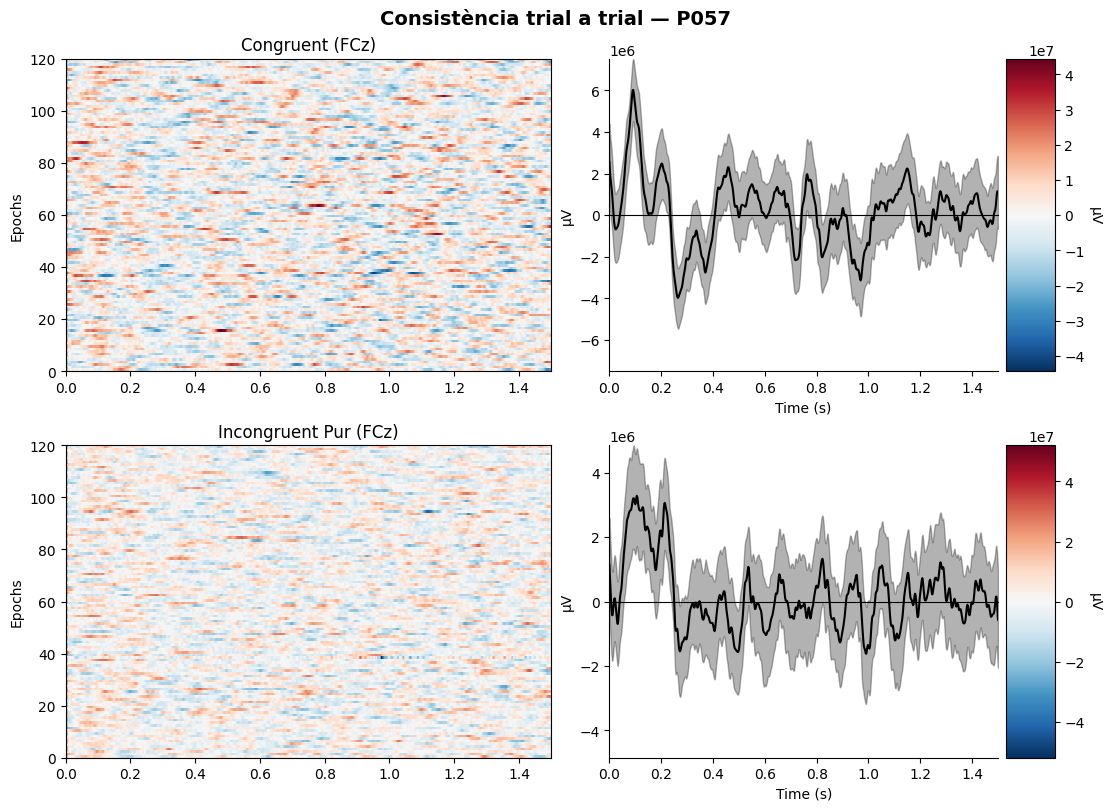

In [15]:
# Cada condició necessita 3 axes: [imatge, erp, colorbar]
fig = plt.figure(figsize=(11, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1)

# Subgrid esquerra (Congruent): 3 columnes internes
gs_c = gs[0].subgridspec(1, 3, width_ratios=[5, 4, 0.5])
gs_ip = gs[1].subgridspec(1, 3, width_ratios=[5, 4, 0.5])

axes_c = [fig.add_subplot(gs_c[i]) for i in range(3)]
axes_ip = [fig.add_subplot(gs_ip[i]) for i in range(3)]

mne.viz.plot_epochs_image(
    ep_c, picks="FCz", title=f"Congruent (FCz)", axes=axes_c, show=False, combine=None, cmap="RdBu_r"
)
mne.viz.plot_epochs_image(
    ep_ip, picks="FCz", title=f"Incongruent Pur (FCz)", axes=axes_ip, show=False, combine=None, cmap="RdBu_r"
)

fig.suptitle(f"Consistència trial a trial — {subj_name}", fontsize=14, fontweight="bold")
plt.savefig(FIGURES_DIR / f"erp_images_{subj_name}.png", dpi=300)
plt.show()

En el Congruent, hi ha un pic d'activitat més marcat als primers 100ms (6 vs 3 μV) i en general una activitat més intensa i concentrada en el temps. En canvi, en l'Incongruent, hi ha una oscil·lació més irregular i incerta.

## 14. Galàxia de Riemann (Projecció PCA de l'Espai Tangent)

**L'Explicació Tècnica:** Utilitzem Matrius d'Estimació de Covariàncies Espacials (SPD) les quals ignoren totalment el component estricte del "temps" i capturen informació estructural interna de les respostes globals per un sol iterant subjecte. Com viuen a un espai i mètrica topològica deformada complexa de *Riemann* el vectoriza per un espai projectual rígid al *TangentSpace* que ho dimensiona forçat per veure un tall líneal del pla hiper-dimensional via SVM mitjançant visualització de 2 i 3 components *PCA*.

**En llenguatge més planer:** Igual que veiem quan ens volen fer mapes del planeta terra reals o plans sense falssejar formes. Aquí les "onades" cerebrals són rugositats súper complexes que la IA no sabria dibuixar a primera ullada i les perdríem de vista. El que fa l'equació és planxar els plecs d'activació sobre una tauleta de paper llisa en format de punts de coordenades estables i aïllades al laboratori virtual; llavors nosaltres ja podem dibuixar de cop, molt fàcilment, una pinzellada completament dreta on separa els estats "Normal" dels de "Saturació Mentals".


Generant Galàxia de Riemann per al subjecte P057...


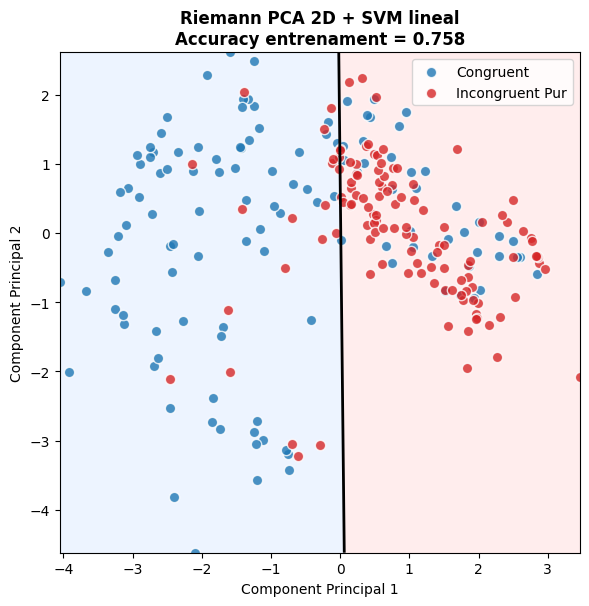

Versió 2D desada a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\riemann_galaxy_2d_P057.png


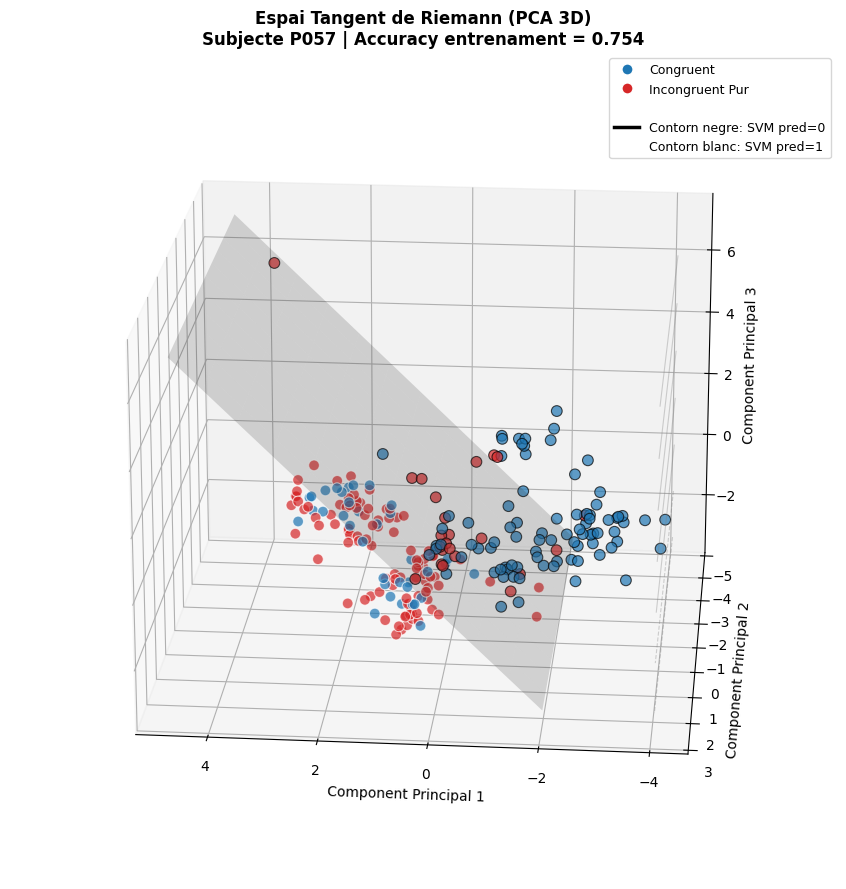

In [16]:
print(f"\nGenerant Galàxia de Riemann per al subjecte {subj_name}...")

# Agafem les dades contínues (Assajos x Canals x Temps)
X_riemann = np.concatenate([ep_c.get_data(), ep_ip.get_data()])
y_riemann = np.concatenate([np.zeros(len(ep_c)), np.ones(len(ep_ip))])

# Pas 1: Calculem les matrius de covariància amb regularització OAS
cov_mats = Covariances(estimator="oas").fit_transform(X_riemann)
# Pas 2: Projectem les covariàncies a l'Espai Tangent (transformació a geometria euclidiana)
tangent_vectors = TangentSpace(metric="riemann").fit_transform(cov_mats)

# Versió 2D: projecció PCA a dos components + frontera lineal simple
pca_2d = PCA(n_components=2)
X_2d = pca_2d.fit_transform(tangent_vectors)
scaler_2d = StandardScaler()
X_2d_z = scaler_2d.fit_transform(X_2d)
svm_2d = LinearSVC(C=1.0, dual=False, max_iter=5000, random_state=RANDOM_STATE)
svm_2d.fit(X_2d_z, y_riemann)
acc_2d = float(np.mean(svm_2d.predict(X_2d_z) == y_riemann))

fig_2d, ax_2d = plt.subplots(figsize=(7.5, 6.5))

x_min, x_max = float(X_2d[:, 0].min()), float(X_2d[:, 0].max())
y_min, y_max = float(X_2d[:, 1].min()), float(X_2d[:, 1].max())
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200),
)
grid = np.c_[xx.ravel(), yy.ravel()]
grid_z = svm_2d.decision_function(scaler_2d.transform(grid)).reshape(xx.shape)

ax_2d.contourf(xx, yy, grid_z, levels=[-1e9, 0.0, 1e9], colors=["#d8e8ff", "#ffd8d8"], alpha=0.45)
ax_2d.contour(xx, yy, grid_z, levels=[0.0], colors="black", linewidths=2)
ax_2d.scatter(
    X_2d[y_riemann == 0, 0],
    X_2d[y_riemann == 0, 1],
    c="tab:blue",
    label="Congruent",
    alpha=0.8,
    edgecolors="white",
    s=55,
)
ax_2d.scatter(
    X_2d[y_riemann == 1, 0],
    X_2d[y_riemann == 1, 1],
    c="tab:red",
    label="Incongruent Pur",
    alpha=0.8,
    edgecolors="white",
    s=55,
)
ax_2d.set_title(f"Riemann PCA 2D + SVM lineal\nAccuracy entrenament = {acc_2d:.3f}", fontweight="bold")
ax_2d.set_xlabel("Component Principal 1")
ax_2d.set_ylabel("Component Principal 2")
ax_2d.legend(loc="best", frameon=True)
ax_2d.set_aspect("equal", adjustable="box")
out_riemann_2d = FIGURES_DIR / f"riemann_galaxy_2d_{subj_name}.png"
plt.savefig(out_riemann_2d, dpi=300, bbox_inches="tight")
plt.show()
print(f"Versió 2D desada a: {out_riemann_2d}")

# Versió 3D: amb angle fixat (elev=20, azim=95) i contorns blanc-negre
pca_3d = PCA(n_components=3)
X_3d = pca_3d.fit_transform(tangent_vectors)
X_c_3d = X_3d[y_riemann == 0]
X_ip_3d = X_3d[y_riemann == 1]

scaler_3d = StandardScaler()
X_3d_z = scaler_3d.fit_transform(X_3d)
svm_3d = LinearSVC(C=1.0, dual=False, max_iter=5000, random_state=RANDOM_STATE)
svm_3d.fit(X_3d_z, y_riemann)
w_z = svm_3d.coef_[0]
b_z = float(svm_3d.intercept_[0])
w = w_z / scaler_3d.scale_
b = b_z - float(np.dot(w_z, scaler_3d.mean_ / scaler_3d.scale_))

# Prediccions al espai original (no escalat)
pred_3d = svm_3d.predict(X_3d_z)
correct_3d = pred_3d == y_riemann
acc_3d = float(np.mean(correct_3d))

plane_color = "#2f2f2f"
margin_color = "#808080"
x_lim = np.array([X_3d[:, 0].min(), X_3d[:, 0].max()])
y_lim = np.array([X_3d[:, 1].min(), X_3d[:, 1].max()])
z_lim = np.array([X_3d[:, 2].min(), X_3d[:, 2].max()])

# Dibuix amb angle fixat
elev_fixed = 20
azim_fixed = 95

fig = plt.figure(figsize=(10, 9))
ax = fig.add_subplot(111, projection="3d")

# Separem per predicció del SVM (no per correcció)
# pred==0: Congruent correcte + Incongruent Pur incorrecte → contorn negre
# pred==1: Congruent incorrecte + Incongruent Pur correcte → contorn blanc
pred_0_mask = pred_3d == 0
pred_1_mask = pred_3d == 1

# Punts amb predicció 0 (contorn negre)
ax.scatter(
    X_3d[pred_0_mask, 0],
    X_3d[pred_0_mask, 1],
    X_3d[pred_0_mask, 2],
    c=["tab:blue" if y == 0 else "tab:red" for y in y_riemann[pred_0_mask]],
    label="Predicció SVM = 0 (contorn negre)",
    alpha=0.7,
    edgecolors="black",
    s=60,
    linewidth=0.8,
)

# Punts amb predicció 1 (contorn blanc)
ax.scatter(
    X_3d[pred_1_mask, 0],
    X_3d[pred_1_mask, 1],
    X_3d[pred_1_mask, 2],
    c=["tab:blue" if y == 0 else "tab:red" for y in y_riemann[pred_1_mask]],
    label="Predicció SVM = 1 (contorn blanc)",
    alpha=0.7,
    edgecolors="white",
    s=60,
    linewidth=0.8,
)

# Hiperplà
if abs(w[2]) >= max(abs(w[0]), abs(w[1])):
    xx, yy = np.meshgrid(
        np.linspace(x_lim[0], x_lim[1], 12),
        np.linspace(y_lim[0], y_lim[1], 12),
    )
    zz = -(w[0] * xx + w[1] * yy + b) / w[2]
    ax.plot_surface(xx, yy, zz, alpha=0.18, color=plane_color, linewidth=0, shade=False)
    ax.contour(xx, yy, zz, zdir="z", offset=z_lim[0], colors=margin_color, linewidths=0.8, alpha=0.35)
elif abs(w[1]) >= abs(w[0]):
    xx, zz = np.meshgrid(
        np.linspace(x_lim[0], x_lim[1], 12),
        np.linspace(z_lim[0], z_lim[1], 12),
    )
    yy = -(w[0] * xx + w[2] * zz + b) / w[1]
    ax.plot_surface(xx, yy, zz, alpha=0.18, color=plane_color, linewidth=0, shade=False)
    ax.contour(xx, yy, zz, zdir="y", offset=y_lim[0], colors=margin_color, linewidths=0.8, alpha=0.35)
else:
    yy, zz = np.meshgrid(
        np.linspace(y_lim[0], y_lim[1], 12),
        np.linspace(z_lim[0], z_lim[1], 12),
    )
    xx = -(w[1] * yy + w[2] * zz + b) / w[0]
    ax.plot_surface(xx, yy, zz, alpha=0.18, color=plane_color, linewidth=0, shade=False)
    ax.contour(xx, yy, zz, zdir="x", offset=x_lim[0], colors=margin_color, linewidths=0.8, alpha=0.35)

ax.set_title(
    f"Espai Tangent de Riemann (PCA 3D)\nSubjecte {subj_name} | Accuracy entrenament = {acc_3d:.3f}",
    fontweight="bold",
)
ax.set_xlabel("Component Principal 1")
ax.set_ylabel("Component Principal 2")
ax.set_zlabel("Component Principal 3")
ax.view_init(elev=elev_fixed, azim=azim_fixed)

# Leyenda personalizada amb colors de classes
from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="tab:blue", markersize=8, label="Congruent"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="tab:red", markersize=8, label="Incongruent Pur"),
    Line2D([0], [0], color="w", linewidth=0, label=""),  # espai
    Line2D([0], [0], color="black", linewidth=2.5, label="Contorn negre: SVM pred=0"),
    Line2D([0], [0], color="white", linewidth=2.5, label="Contorn blanc: SVM pred=1"),
]
ax.legend(handles=legend_elements, loc="upper right", frameon=True, fontsize=9)
plt.tight_layout()

out_riemann_3d = FIGURES_DIR / f"riemann_galaxy_3d_{subj_name}.png"
plt.savefig(out_riemann_3d, dpi=300, bbox_inches="tight")
plt.show()

## 15. Graf de Connectivitat Circular

**L'Explicació Tècnica:** Un graf circular funcional aplicant càlcul pur sobre PLV (*Phase Locking Value*). En comptes de mirar qui escup més electricitat (amplitud) mirem les variacions i canvis sobre *quines àrees interactuen amb una oscil·lació harmònica freqüencial constant de l'un l'altre i es correlacionen de costat en costat durant un subjecte limitant-se l'època i la resolució d'amplitud a la banda on sabem que tenim conflict interocular (0.2 fins a 0.8 en banda 5Hz a 7Hz de Theta)*.
*(⭐ Forma d'estendre-ho fàcilment: Com hem fet als TGM inicials on es restant valors. Produir l'adjacency-matrix IP gran grupal dels subjectes i sostreure o treure-hi el valor total de Condició C deixaria perfectament ressaltals aquells canals únics que la ment encèn i obliga a moure pel moment el cervell pel conflicte amb exclusivitat)*

**En llenguatge més planer:** Observes rutes i xarxes d'aeroports. Enlloc de llistar el punt físic del cap què dona més calor o febre a la gràfica d'un xip temporal, es connecten mitjançant filaments invisibles les ciutats / estacions del cervell que "parlen o ploren a base d'escriure alhora al mateix ritme". Veient exactament les rutes d'anada i línies i les subrutines i bucles on més xerraven i enviaven cotxes mentrestant la part conscient intentava arreglar la confusibilitat a dalt del cap en el moment de l'experiment in-situ.


Generant Graf de Connectivitat Circular (Banda Theta)...


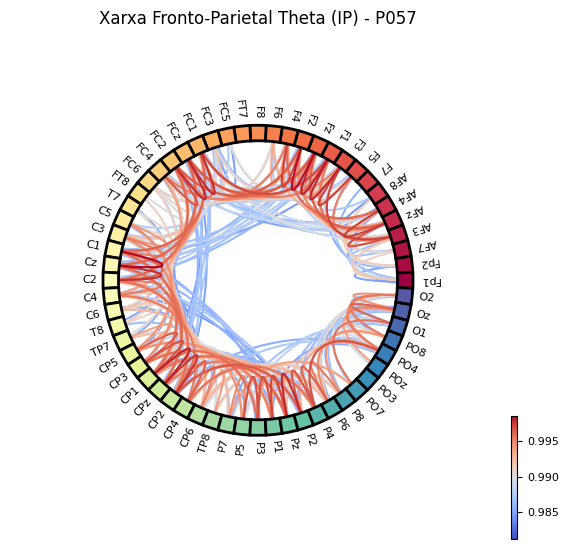

Graf de Connectivitat desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\connectivity_circle_P057.png


In [17]:
# Assegurem que el muntatge estàndard està aplicat per tenir les coordenades físiques correctes
muntatge = mne.channels.make_standard_montage("standard_1005")
ep_best.set_montage(muntatge, match_case=False, on_missing="ignore")

ep_c = ep_best[y_best == 0]
ep_ip = ep_best[y_best == 1]

# 7. GRAF DE CONNECTIVITAT CIRCULAR (El "Cervell en Xarxa")
print("\nGenerant Graf de Connectivitat Circular (Banda Theta)...")
# 1. Definim els paràmetres de la banda d'interès (Theta: 5-7 Hz)
fmin, fmax = 5.0, 7.0
sfreq = ep_best.info["sfreq"]
# 2. Calculem el Phase Locking Value (PLV) per a la condició Incongruent
# El PLV mesura si dos elèctrodes oscil·len sincronitzadament (comunicació)
con = spectral_connectivity_epochs(
    ep_ip,
    method="plv",
    mode="multitaper",
    sfreq=sfreq,
    fmin=fmin,
    fmax=fmax,
    faverage=True,
    tmin=0.2,
    tmax=0.8,
    mt_adaptive=False,
    n_jobs=6,
    verbose=False,
)
# Extraiem la matriu de connectivitat 2D
con_matrix = con.get_data(output="dense")[:, :, 0]
# 3. Preparació estètica del graf
ch_names = ep_best.ch_names

# Com que 60 elèctrodes generen milers de línies, només dibuixarem les 20 més fortes
fig, ax = plt.subplots(figsize=(8, 8), facecolor="white", subplot_kw=dict(polar=True))
plot_connectivity_circle(
    con_matrix,
    ch_names,
    n_lines=300,
    title=f"Xarxa Fronto-Parietal Theta (IP) - {subj_name}",
    facecolor="white",
    textcolor="black",
    node_edgecolor="black",
    colormap="coolwarm",
    vmin=np.percentile(con_matrix, 90),
    vmax=np.max(con_matrix),
    ax=ax,
    show=False,
)
out_conn = FIGURES_DIR / f"connectivity_circle_{subj_name}.png"
fig.savefig(out_conn, dpi=300, facecolor="white", bbox_inches="tight")
plt.show()
print(f"Graf de Connectivitat desat a: {out_conn}")

## 16. Mapa Cortical 3D - Localització de les fonts

**L'Explicació Tècnica:** Una projecció de les dades d'eix EEG cap a estructures d'apariència neuronal complexes generades usant *Forward i Solucions del Problema Invers (Algoritme dSPM per fonts de modelat estadístic per subjectes tipus "fsaverage")*. Aplica les regles de viatge elèctric de conduir del cap que sabem per moure's directament contra la direcció al nucli evitant corrupcions al predir segons l'estudi real de soroll `noise_cov` què està actiu sota una franja del vector.
*(⭐ Forma d'estendre-ho fàcilment: Com que al començar de les proves estem fent ús explícit només de 1 sol subjecte de nou... Es podrien reconstruir les STC purament pròpies als respectius orígens i finalment promejar per produir l'"averatge invers" llevant el pes espuri local i oferir una fotografia totalment global i sòlida general representant on es detona la regió de l'estrès.)*

**En llenguatge més planer:** És conegut a d'àmbit analític pur com el Problema Invers. Visualitzem metafòricament un edifici; nosaltres només tenim registres externament penjats a fóra per detectar i gravar tot allò general d'activació. Ara agafem i introduïm intel·ligència amb modelatge pur sobre tots i cada un dels rebots del cervell contra l'espai pel cap pla. Finalment dedüim al buit per l'"eco" els emplaçaments que "farien cridar exactament" de certa gravetat per recrear la simetria de les ones que capturàvem a cegues pel microscopi cranial de sensors posats la pell! S'endinsa en 3 Dimensions a l'escorça!

Pic d'activitat trobat automàticament a: 1.160 s
Renderitzant mapa cortical 2D...


Pic d'activitat trobat automàticament a: 1.160 s
Renderitzant mapa cortical 2D...


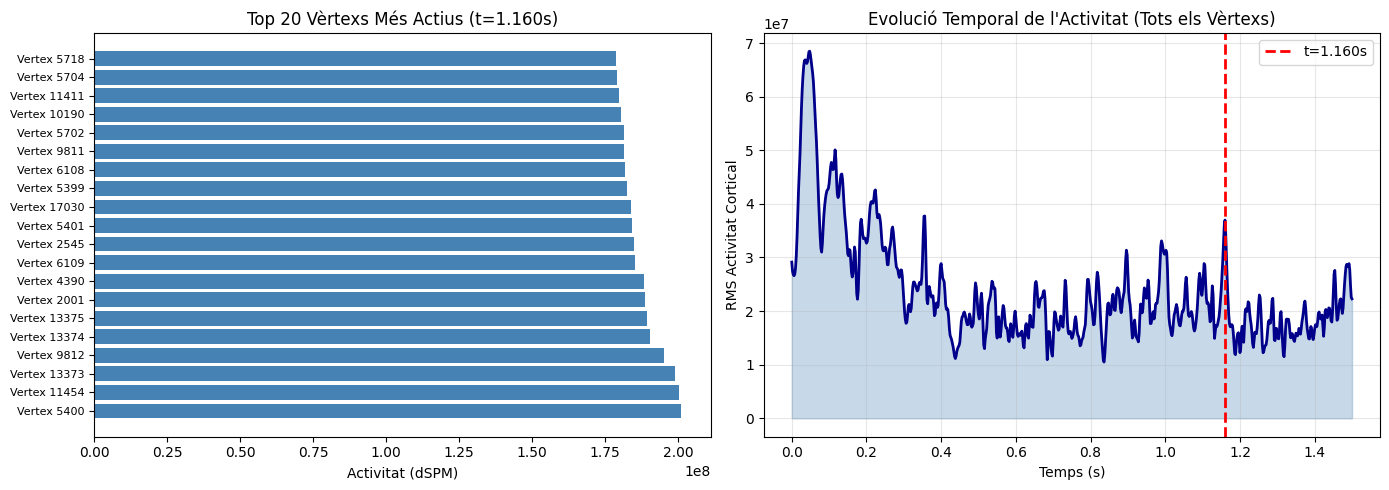

Pic d'activitat trobat automàticament a: 1.160 s
Renderitzant mapa cortical 2D...


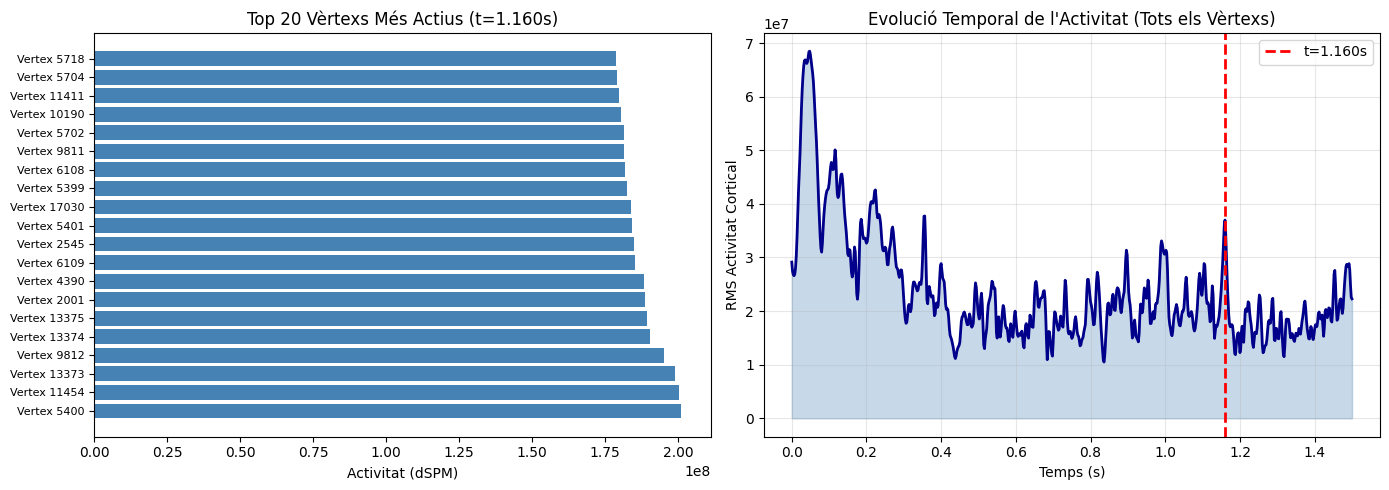

Mapa cortical 2D (fallback) desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\3d_cortical_map_P057_2d_fallback.png
Prenent fotografies 3D d'alta resolució (això pot trigar uns segons)...
Muntant el llenç final...


Pic d'activitat trobat automàticament a: 1.160 s
Renderitzant mapa cortical 2D...


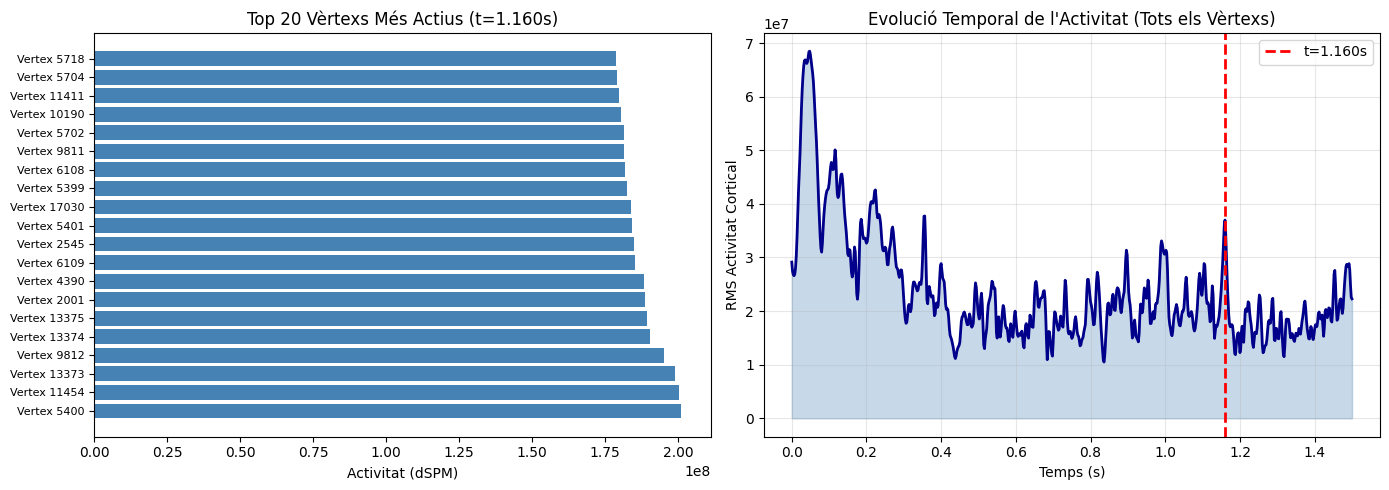

Mapa cortical 2D (fallback) desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\3d_cortical_map_P057_2d_fallback.png
Prenent fotografies 3D d'alta resolució (això pot trigar uns segons)...
Muntant el llenç final...


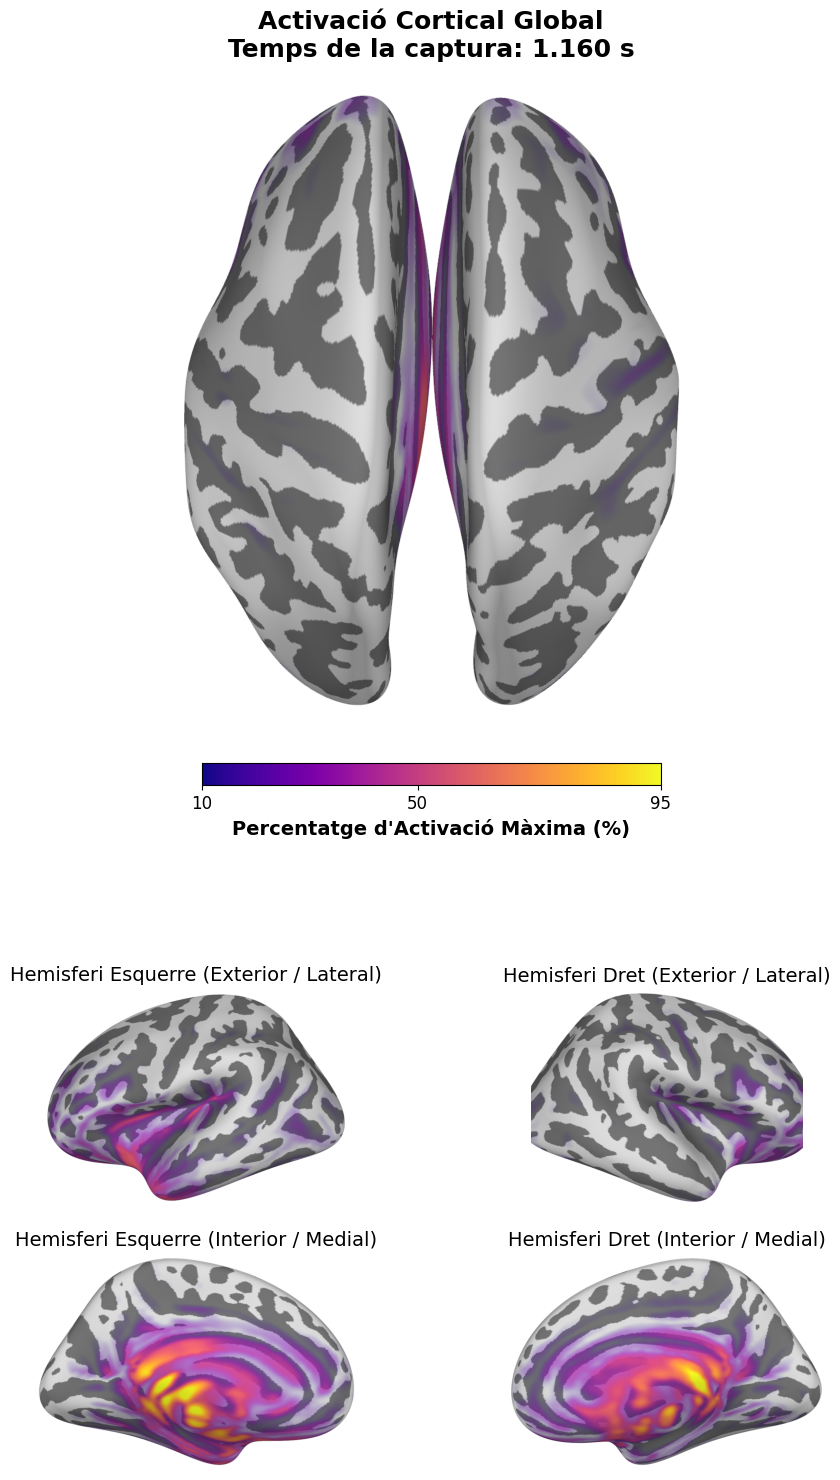

Pòster definitiu desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\3d_master_panel_P057.png


In [123]:
# 1. Carreguem l'anatomia estàndard de MNE (fsaverage)
fs_dir = fetch_fsaverage(verbose=False)
subjects_dir = os.path.dirname(fs_dir)
subject = "fsaverage"

# Rutes als models físics del cap
trans = "fsaverage"  # Transformació d'identitat per defecte
src = os.path.join(fs_dir, "bem", "fsaverage-ico-5-src.fif")
bem = os.path.join(fs_dir, "bem", "fsaverage-5120-5120-5120-bem-sol.fif")

# 2. Preparem les dades (Calculem l'Evocat de la condició Incongruent)
evoked = ep_ip.average()
evoked.set_eeg_reference(projection=True)

# 3. Model de Soroll (Covariància)
# Com que no tenim minuts d'EEG en repòs, fem una covariància "Ad Hoc" de l'època mateixa
noise_cov = mne.make_ad_hoc_cov(evoked.info)

# 4. Solució Directa (Forward Solution): Com viatja el senyal des del cervell fins al casc
fwd = mne.make_forward_solution(evoked.info, trans=trans, src=src, bem=bem, eeg=True, verbose=False)

# 5. L'Operador Invers: El model matemàtic per "endevinar" el cervell a partir de l'EEG
inverse_operator = make_inverse_operator(evoked.info, fwd, noise_cov, loose=0.2, depth=0.8, verbose=False)

# 6. Apliquem el model per trobar l'activitat cerebral pura (Mètode dSPM)
method = "dSPM"
snr = 3.0
lambda2 = 1.0 / snr**2
stc = apply_inverse(evoked, inverse_operator, lambda2, method=method, pick_ori=None, verbose=False)

# 7. Renderitzat 3D amb fallback a matplotlib
t_peak = 0.45
print("Renderitzant mapa cortical...")

# Extraiem el pic d'activitat al temps especificat
time_idx = np.argmin(np.abs(stc.times - t_peak))
data_peak = stc.data[:, time_idx]

# Dibuixem un gràfic de barres de les regions més actives
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gràfic 1: Distribució d'activitat cerebral
top_n = 20
top_indices = np.argsort(np.abs(data_peak))[-top_n:]
top_values = data_peak[top_indices]

ax1.barh(range(len(top_values)), np.abs(top_values), color="steelblue")
ax1.set_yticks(range(len(top_values)))
ax1.set_yticklabels([f"Vertex {i}" for i in top_indices], fontsize=8)
ax1.set_xlabel("Activitat (dSPM)")
ax1.set_title(f"Top {top_n} Vèrtexs Més Actius (t={t_peak:.3f}s)")
ax1.invert_yaxis()

# Gràfic 2: Evolució temporal de l'activitat global
mean_activity = np.sqrt(np.mean(stc.data**2, axis=0))
ax2.plot(stc.times, mean_activity, linewidth=2, color="darkblue")
ax2.axvline(t_peak, color="red", linestyle="--", linewidth=2, label=f"t={t_peak}s")
ax2.fill_between(stc.times, 0, mean_activity, alpha=0.3, color="steelblue")
ax2.set_xlabel("Temps (s)")
ax2.set_ylabel("RMS Activitat Cortical")
ax2.set_title("Evolució Temporal de l'Activitat (Tots els Vèrtexs)")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
out_brain_2d = FIGURES_DIR / f"3d_cortical_map_{subj_name}_2d_fallback.png"
plt.savefig(out_brain_2d, dpi=300, bbox_inches="tight")
plt.show()
print(f"Mapa cortical 2D (fallback) desat a: {out_brain_2d}")

Pic d'activitat trobat automàticament a: 0.048 s
Ajustant l'escala de colors... Màxim dSPM real: 320111978.84


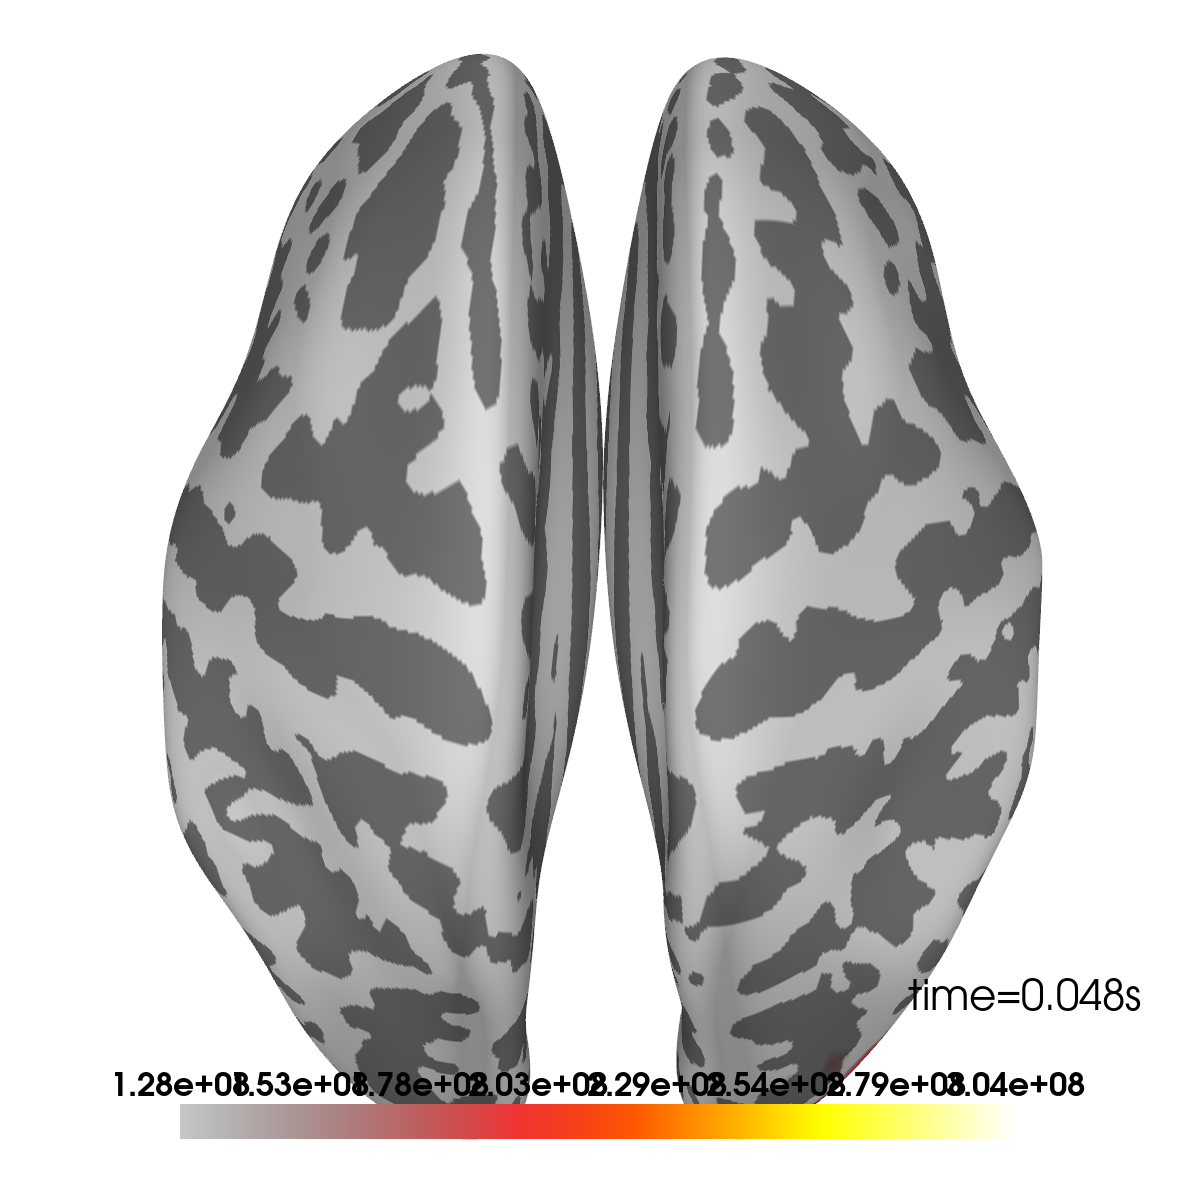

Cervell 3D desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\3d_cortical_map_P057.png


In [25]:
# 1. Carreguem l'anatomia estàndard de MNE (fsaverage)
fs_dir = fetch_fsaverage(verbose=False)
subjects_dir = os.path.dirname(fs_dir)
subject = "fsaverage"

# Rutes als models físics del cap
trans = "fsaverage"  # Transformació d'identitat per defecte
src = os.path.join(fs_dir, "bem", "fsaverage-ico-5-src.fif")
bem = os.path.join(fs_dir, "bem", "fsaverage-5120-5120-5120-bem-sol.fif")

# 2. Preparem les dades (Calculem l'Evocat de la condició Incongruent)
evoked = ep_ip.average()
evoked.set_eeg_reference(projection=True)

# 3. Model de Soroll (Covariància)
# Com que no tenim minuts d'EEG en repòs, fem una covariància "Ad Hoc" de l'època mateixa
noise_cov = mne.make_ad_hoc_cov(evoked.info)

# 4. Solució Directa (Forward Solution): Com viatja el senyal des del cervell fins al casc
fwd = mne.make_forward_solution(evoked.info, trans=trans, src=src, bem=bem, eeg=True, verbose=False)

# 5. L'Operador Invers: El model matemàtic per "endevinar" el cervell a partir de l'EEG
inverse_operator = make_inverse_operator(evoked.info, fwd, noise_cov, loose=0.2, depth=0.8, verbose=False)

# 6. Apliquem el model per trobar l'activitat cerebral pura (Mètode dSPM)
method = "dSPM"
snr = 3.0
lambda2 = 1.0 / snr**2
stc = apply_inverse(evoked, inverse_operator, lambda2, method=method, pick_ori=None, verbose=False)

### Entre 0.3 i 1s

Pic d'activitat trobat a: 0.99 s
Prenent fotografies 3D d'alta resolució (això pot trigar uns segons)...
Muntant el llenç final...


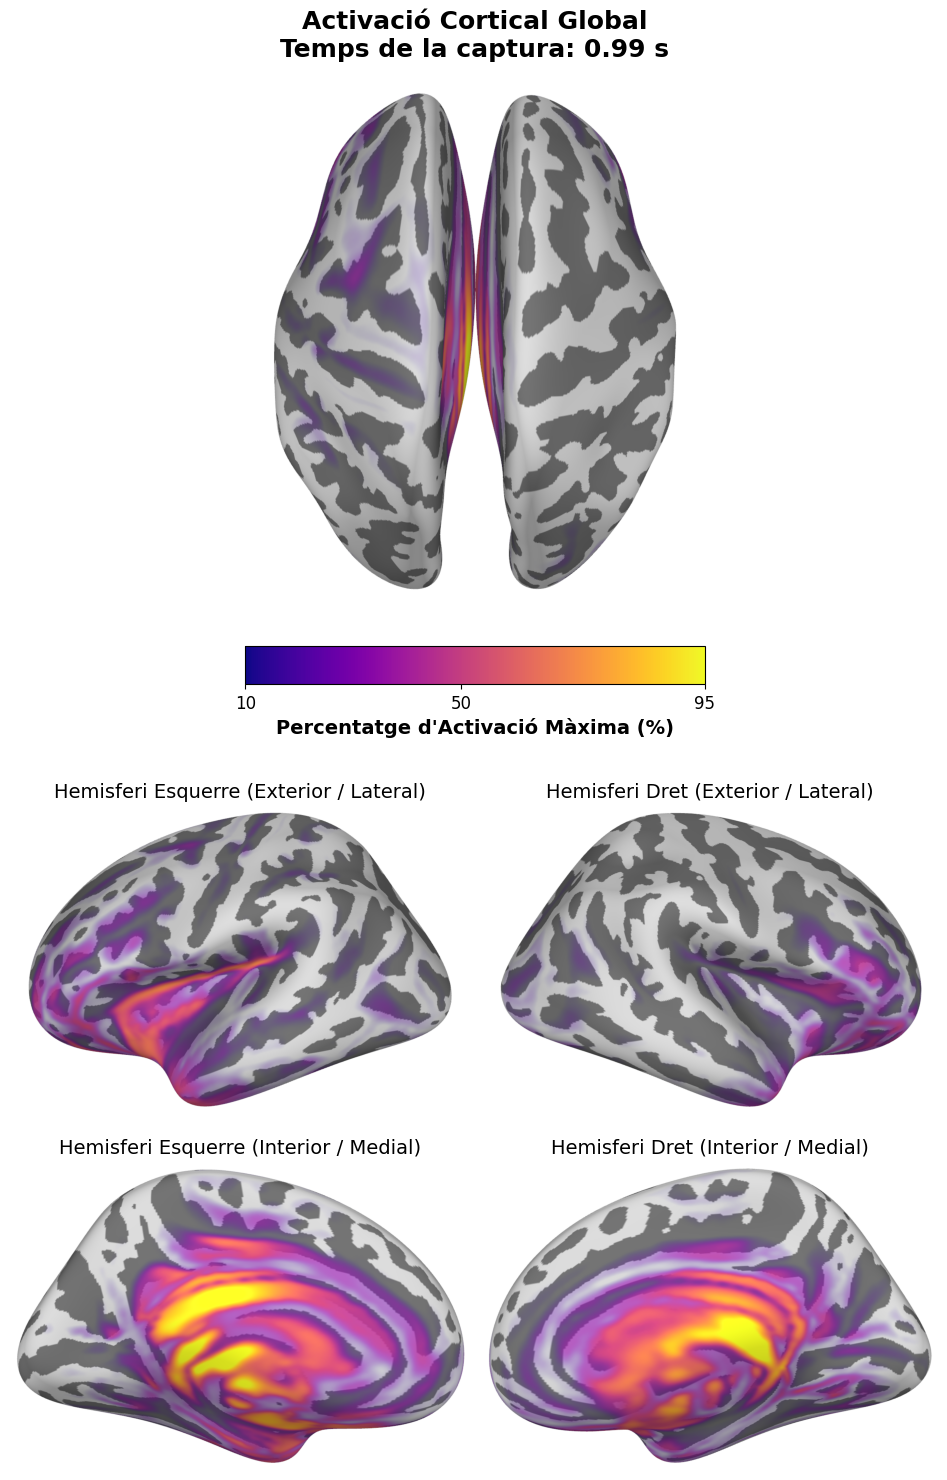

Pòster definitiu desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\3d_master_panel_P057_0.99.png


In [135]:
# 1. Preparació de les dades
mne.viz.set_3d_backend("pyvistaqt")
stc_plot = stc.copy()

# Elimino top 0.3% de valors que considero outliers (3 sigmes)
robust_max = np.percentile(stc_plot.data, 99.7)
stc_plot.data = (stc_plot.data / robust_max) * 100

t_inici, t_fi = 0.3, 1.0
ch_idx, t_peak = stc_plot.get_peak(hemi=None, tmin=t_inici, tmax=t_fi)
print(f"Pic d'activitat trobat a: {t_peak:.2f} s")

limits = [10, 50, 95]
llindars = dict(kind="value", lims=limits)

# 2. Motor de Renders (Sense mostrar les finestres 3D, només fa "fotos")
render_kwargs = dict(
    subject=subject,
    subjects_dir=subjects_dir,
    initial_time=t_peak,
    surface="inflated",
    clim=llindars,
    colormap="plasma",
    smoothing_steps=10,
    time_viewer=False,
    show_traces=False,
    background="w",
    size=(800, 800),
    colorbar=False,
)


def captura_i_retalla(hemi, vista):
    """Genera el cervell, fa la foto i retalla l'excés d'espai blanc."""
    brain = stc_plot.plot(hemi=hemi, views=vista, **render_kwargs)
    img = brain.screenshot()
    brain.close()

    # Retall geomètric dels marges blancs per poder enganxar bé les fotos
    rgb = img[:, :, :3]
    non_white = np.any(rgb < 250, axis=-1)
    rows = np.any(non_white, axis=1)
    cols = np.any(non_white, axis=0)

    if not np.any(rows):
        return img  # Seguretat
    ymin, ymax = np.where(rows)[0][[0, -1]]
    xmin, xmax = np.where(cols)[0][[0, -1]]
    m = 20  # Marge en píxels
    return img[max(0, ymin - m) : ymax + m, max(0, xmin - m) : xmax + m]


print("Prenent fotografies 3D d'alta resolució (això pot trigar uns segons)...")
img_dor = captura_i_retalla("both", "dorsal")
img_lat_l = captura_i_retalla("lh", "lateral")
img_lat_r = captura_i_retalla("rh", "lateral")
img_med_l = captura_i_retalla("lh", "medial")
img_med_r = captura_i_retalla("rh", "medial")

# ==============================================================================
# 3. MUNTATGE DEL PÒSTER FINAL AMB MATPLOTLIB
# ==============================================================================
print("Muntant el llenç final...")
fig = plt.figure(figsize=(12, 18))
gs = gridspec.GridSpec(5, 4, height_ratios=[2, 0.15, 0.1, 1.2, 1.2], hspace=0.2, wspace=0.05)

# --- A) Vista d'Ocell (Dorsal) ocupant tota la fila superior ---
ax_dor = fig.add_subplot(gs[0, :])
ax_dor.imshow(img_dor)
ax_dor.axis("off")
ax_dor.set_title(
    f"Activació Cortical Global\nTemps de la captura: {t_peak:.2f} s", fontsize=18, fontweight="bold", pad=20
)

# --- B) Llegenda Comuna (Colorbar) grossa al mig ---
ax_cbar = fig.add_subplot(gs[1, 1:3])
cmap = plt.get_cmap("plasma")
norm = mpl.colors.Normalize(vmin=limits[0], vmax=limits[2])
cbar = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), cax=ax_cbar, orientation="horizontal")
cbar.set_label("Percentatge d'Activació Màxima (%)", fontsize=14, fontweight="bold")
cbar.set_ticks(limits)
cbar.ax.tick_params(labelsize=12)

# --- C) Vistes Laterals (Exterior) ---
ax_ll = fig.add_subplot(gs[3, 0:2])
ax_ll.imshow(img_lat_l)
ax_ll.axis("off")
ax_ll.set_title("Hemisferi Esquerre (Exterior / Lateral)", fontsize=14)

ax_rl = fig.add_subplot(gs[3, 2:4])
ax_rl.imshow(img_lat_r)
ax_rl.axis("off")
ax_rl.set_title("Hemisferi Dret (Exterior / Lateral)", fontsize=14)

# --- D) Vistes Medials (Interior "tallat") ---
ax_ml = fig.add_subplot(gs[4, 0:2])
ax_ml.imshow(img_med_l)
ax_ml.axis("off")
ax_ml.set_title("Hemisferi Esquerre (Interior / Medial)", fontsize=14)

ax_mr = fig.add_subplot(gs[4, 2:4])
ax_mr.imshow(img_med_r)
ax_mr.axis("off")
ax_mr.set_title("Hemisferi Dret (Interior / Medial)", fontsize=14)

# Guardem la figura mestra
out_master = FIGURES_DIR / f"3d_master_panel_{subj_name}_{t_peak:.2f}.png"
plt.savefig(out_master, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print(f"Pòster definitiu desat a: {out_master}")

### Entre 0.5 i 1.5s

Pic d'activitat trobat a: 1.16 s
Prenent fotografies 3D d'alta resolució (això pot trigar uns segons)...
Muntant el llenç final...


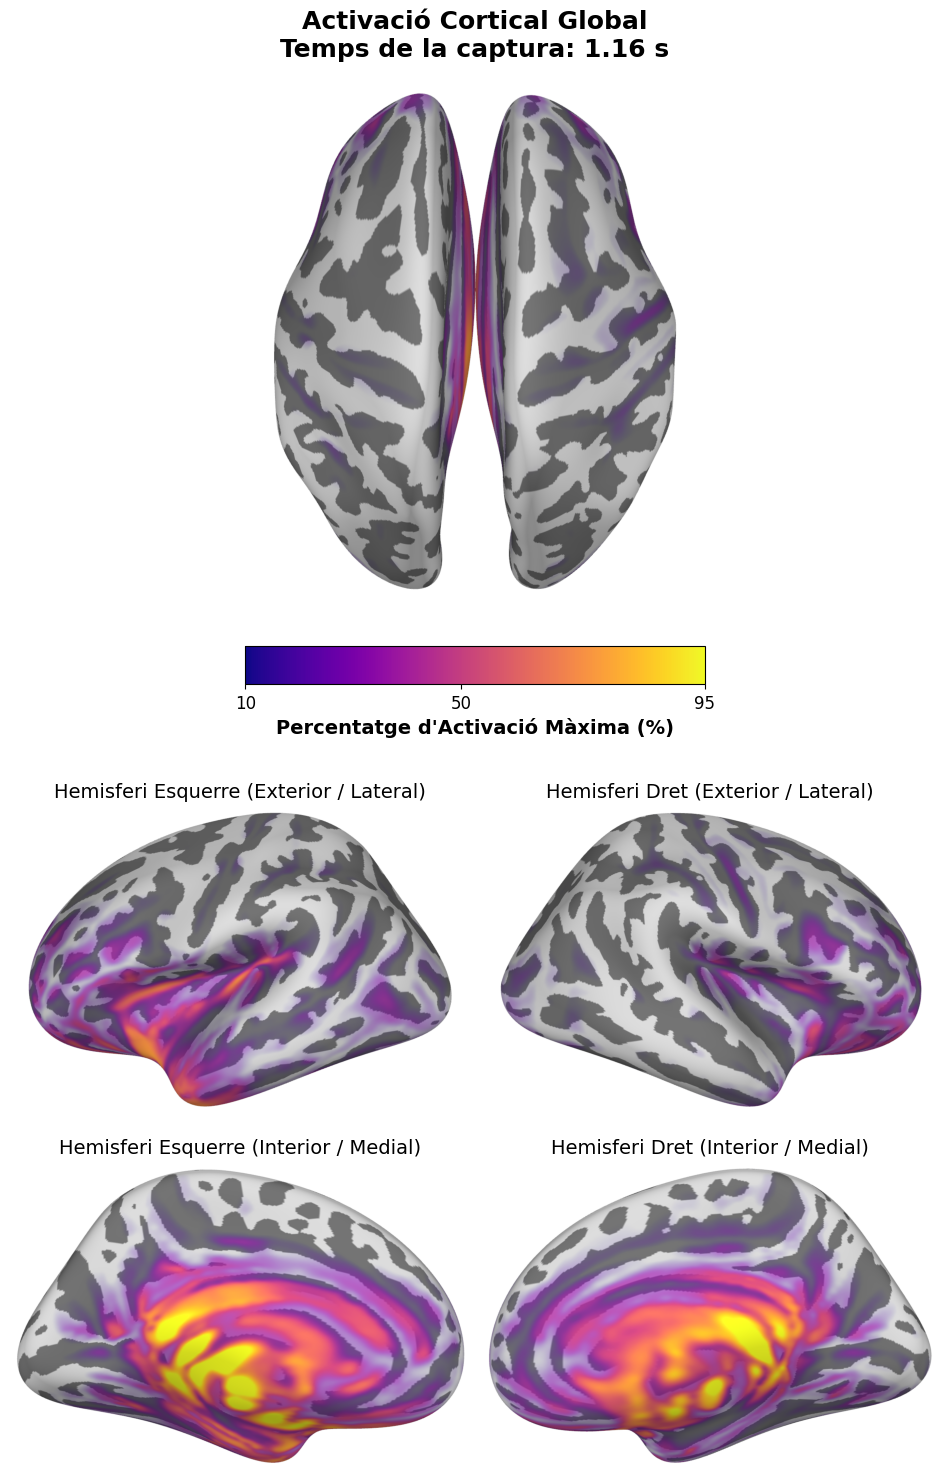

Pòster definitiu desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\3d_master_panel_P057_1.16.png


In [134]:
# 1. Preparació de les dades
mne.viz.set_3d_backend("pyvistaqt")
stc_plot = stc.copy()

# Elimino top 0.3% de valors que considero outliers (3 sigmes)
robust_max = np.percentile(stc_plot.data, 99.7)
stc_plot.data = (stc_plot.data / robust_max) * 100

t_inici, t_fi = 0.5, 1.5
ch_idx, t_peak = stc_plot.get_peak(hemi=None, tmin=t_inici, tmax=t_fi)
print(f"Pic d'activitat trobat a: {t_peak:.2f} s")

llindars = dict(kind="value", lims=limits)

# 2. Motor de Renders (Sense mostrar les finestres 3D, només fa "fotos")
render_kwargs = dict(
    subject=subject,
    subjects_dir=subjects_dir,
    initial_time=t_peak,
    surface="inflated",
    clim=llindars,
    colormap="plasma",
    smoothing_steps=10,
    time_viewer=False,
    show_traces=False,
    background="w",
    size=(800, 800),
    colorbar=False,
)


def captura_i_retalla(hemi, vista):
    """Genera el cervell, fa la foto i retalla l'excés d'espai blanc."""
    brain = stc_plot.plot(hemi=hemi, views=vista, **render_kwargs)
    img = brain.screenshot()
    brain.close()

    # Retall geomètric dels marges blancs per poder enganxar bé les fotos
    rgb = img[:, :, :3]
    non_white = np.any(rgb < 250, axis=-1)
    rows = np.any(non_white, axis=1)
    cols = np.any(non_white, axis=0)

    if not np.any(rows):
        return img  # Seguretat
    ymin, ymax = np.where(rows)[0][[0, -1]]
    xmin, xmax = np.where(cols)[0][[0, -1]]
    m = 20  # Marge en píxels
    return img[max(0, ymin - m) : ymax + m, max(0, xmin - m) : xmax + m]


print("Prenent fotografies 3D d'alta resolució (això pot trigar uns segons)...")
img_dor = captura_i_retalla("both", "dorsal")
img_lat_l = captura_i_retalla("lh", "lateral")
img_lat_r = captura_i_retalla("rh", "lateral")
img_med_l = captura_i_retalla("lh", "medial")
img_med_r = captura_i_retalla("rh", "medial")

# ==============================================================================
# 3. MUNTATGE DEL PÒSTER FINAL AMB MATPLOTLIB
# ==============================================================================
print("Muntant el llenç final...")
fig = plt.figure(figsize=(12, 18))
gs = gridspec.GridSpec(5, 4, height_ratios=[2, 0.15, 0.1, 1.2, 1.2], hspace=0.2, wspace=0.05)

# --- A) Vista d'Ocell (Dorsal) ocupant tota la fila superior ---
ax_dor = fig.add_subplot(gs[0, :])
ax_dor.imshow(img_dor)
ax_dor.axis("off")
ax_dor.set_title(
    f"Activació Cortical Global\nTemps de la captura: {t_peak:.2f} s", fontsize=18, fontweight="bold", pad=20
)

# --- B) Llegenda Comuna (Colorbar) grossa al mig ---
ax_cbar = fig.add_subplot(gs[1, 1:3])
cmap = plt.get_cmap("plasma")
norm = mpl.colors.Normalize(vmin=limits[0], vmax=limits[2])
cbar = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), cax=ax_cbar, orientation="horizontal")
cbar.set_label("Percentatge d'Activació Màxima (%)", fontsize=14, fontweight="bold")
cbar.set_ticks(limits)
cbar.ax.tick_params(labelsize=12)

# --- C) Vistes Laterals (Exterior) ---
ax_ll = fig.add_subplot(gs[3, 0:2])
ax_ll.imshow(img_lat_l)
ax_ll.axis("off")
ax_ll.set_title("Hemisferi Esquerre (Exterior / Lateral)", fontsize=14)

ax_rl = fig.add_subplot(gs[3, 2:4])
ax_rl.imshow(img_lat_r)
ax_rl.axis("off")
ax_rl.set_title("Hemisferi Dret (Exterior / Lateral)", fontsize=14)

# --- D) Vistes Medials (Interior "tallat") ---
ax_ml = fig.add_subplot(gs[4, 0:2])
ax_ml.imshow(img_med_l)
ax_ml.axis("off")
ax_ml.set_title("Hemisferi Esquerre (Interior / Medial)", fontsize=14)

ax_mr = fig.add_subplot(gs[4, 2:4])
ax_mr.imshow(img_med_r)
ax_mr.axis("off")
ax_mr.set_title("Hemisferi Dret (Interior / Medial)", fontsize=14)

# Guardem la figura mestra
out_master = FIGURES_DIR / f"3d_master_panel_{subj_name}_{t_peak:.2f}.png"
plt.savefig(out_master, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print(f"Pòster definitiu desat a: {out_master}")

Amb aquest plot podem veure molt clarament la hipòtesi que l'ACC (Anterior Cingulate Cortex) és la regió més activa en el contrast Congruent vs Incongruent Pur. L'escorça del cervell té poca activitat, però al voltant de l'ACC passa tot el contrari.